### Base Setup

In [1]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
import os
import glob
import pandas as pd
import numpy as np

# --- 1. Load Data ---
strategies = ["strategy_one", "strategy_two", "strategy_three", "strategy_four"]
dfs = []

for strategy in strategies:
    results_path = f"{strategy}/{strategy}_results/"
    csv_files = glob.glob(os.path.join(results_path, "results_*.csv"))
    
    for f in csv_files:
        df = pd.read_csv(f)
        # Ensure the 'strategy' column exists and is correctly labeled
        df['strategy'] = strategy
        
        # Handle Strategy 4 categorical context
        if strategy == "strategy_four" and 'user_preference_type' in df.columns:
            # Map 'Minimize Infection' to 0 and 'Minimize NPI' to 1
            df['user_preference_type_numeric'] = df['user_preference_type'].map({
                'Minimize Infection': 0,
                'Minimize NPI': 1
            })
        
        dfs.append(df)

if dfs:
    full_results_df = pd.concat(dfs, ignore_index=True)
    print(f"Loaded {len(full_results_df)} records across {len(dfs)} CSV files from {len(strategies)} strategies.")
    print(full_results_df.groupby('strategy').size())
else:
    print("No CSV files found.")

Loaded 11224 records across 16 CSV files from 4 strategies.
strategy
strategy_four     2880
strategy_one      1439
strategy_three    2590
strategy_two      4315
dtype: int64


In [3]:
def extract_strategy_number(strategy_name):
    """Extract numeric value from strategy name for proper sorting."""
    word_to_num = {
        'one': 1, 'two': 2, 'three': 3, 'four': 4, 'five': 5,
        'six': 6, 'seven': 7, 'eight': 8, 'nine': 9, 'ten': 10
    }
    strategy_lower = str(strategy_name).lower()
    digits = ''.join(filter(str.isdigit, strategy_lower))
    if digits:
        return int(digits)
    for word, num in word_to_num.items():
        if word in strategy_lower:
            return num
    return None

def format_strategy_name(strategy_name):
    """Format strategy name to use words instead of digits."""
    num_to_word = {
        1: "One", 2: "Two", 3: "Three", 4: "Four", 5: "Five",
        6: "Six", 7: "Seven", 8: "Eight", 9: "Nine", 10: "Ten"
    }
    strategy_num = extract_strategy_number(strategy_name)
    if strategy_num in num_to_word:
        return f"Strategy {num_to_word[strategy_num]}"
    return str(strategy_name).replace("_", " ").title()

### Strategy One Analysis (Baseline)

In [4]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_auc_score  # AUROC uses y_true + y_score/probabilities [web:69]


def run_dce_logit_zscore_interaction_with_auroc(
    results_df,
    strategy="strategy_one",
    detailed=False,
    min_obs=10,
    plot=True,
    show_tables=True
):
    # --- Robust display/printing (Jupyter vs script) ---
    def show_df(df, title):
        if not show_tables:
            return
        print("\n" + "=" * 60)
        print(title)
        print("=" * 60)
        try:
            from IPython.display import display  # common in notebooks [web:84]
            display(df)
        except Exception:
            # Ensure all columns show in console output [web:97]
            print(df.to_string(index=False))

    # --- Helper: NumPy z-score (mean/std), ignoring NaNs ---
    def np_zscore(series: pd.Series) -> pd.Series:
        arr = np.asarray(series, dtype=float)
        mu = np.nanmean(arr)
        sigma = np.nanstd(arr, ddof=0)
        if (not np.isfinite(sigma)) or sigma == 0:
            return pd.Series(np.full_like(arr, np.nan, dtype=float), index=series.index)
        return pd.Series((arr - mu) / sigma, index=series.index)

    # --- 1. Filter strategy ---
    df = results_df[results_df["strategy"] == strategy].copy()

    # --- 2. Ensure numeric ---
    num_cols = [
        "infection_rate_selected",
        "infection_rate_non_selected",
        "npi_level_selected",
        "npi_level_non_selected",
    ]
    for c in num_cols:
        df[c] = pd.to_numeric(df[c], errors="coerce")

    # --- 3. Binary choice (Option 1 chosen?) ---
    df["choice"] = (df["selected_choice"] == df["pair"].str.split("-").str[0]).astype(int)

    # --- 4. Reconstruct option attributes ---
    df["inf_1"] = np.where(df["choice"] == 1, df["infection_rate_selected"], df["infection_rate_non_selected"])
    df["inf_2"] = np.where(df["choice"] == 1, df["infection_rate_non_selected"], df["infection_rate_selected"])
    df["npi_1"] = np.where(df["choice"] == 1, df["npi_level_selected"], df["npi_level_non_selected"])
    df["npi_2"] = np.where(df["choice"] == 1, df["npi_level_non_selected"], df["npi_level_selected"])

    # --- 5. Difference coding ---
    df["bc_diff"] = df["npi_1"] - df["npi_2"]
    df["inf_diff"] = df["inf_1"] - df["inf_2"]

    print(f"Prepared {len(df)} valid choice tasks.")

    per_model_rows = []

    # pooled predictions for "overall AUROC"
    pooled_y = []
    pooled_score = []
    pooled_n = 0

    # --- 6. Estimate per model ---
    for model_name in df["model"].dropna().unique():
        m_df = df[df["model"] == model_name].dropna(subset=["choice", "bc_diff", "inf_diff"]).copy()
        if len(m_df) < min_obs:
            continue

        # Standardize main effects
        m_df["bc_diff_z"] = np_zscore(m_df["bc_diff"])
        m_df["inf_diff_z"] = np_zscore(m_df["inf_diff"])

        # Interaction (product of standardized variables)
        m_df["bc_x_inf_z"] = m_df["bc_diff_z"] * m_df["inf_diff_z"]

        m_df = m_df.dropna(subset=["choice", "bc_diff_z", "inf_diff_z", "bc_x_inf_z"])
        if len(m_df) < min_obs:
            continue

        if (
            m_df["bc_diff_z"].nunique(dropna=True) <= 1 or
            m_df["inf_diff_z"].nunique(dropna=True) <= 1 or
            m_df["bc_x_inf_z"].nunique(dropna=True) <= 1
        ):
            continue

        X = sm.add_constant(m_df[["bc_diff_z", "inf_diff_z", "bc_x_inf_z"]])
        y = m_df["choice"]

        try:
            res = sm.Logit(y, X).fit(disp=0)

            # Predicted probabilities (scores) for AUROC [web:69]
            y_score = np.asarray(res.predict(X), dtype=float)

            # AUROC per model (needs both classes present)
            auroc = np.nan
            if y.nunique(dropna=True) == 2:
                try:
                    auroc = float(roc_auc_score(y, y_score))
                except Exception:
                    auroc = np.nan

            # add to pooled overall AUROC
            pooled_y.append(y.to_numpy())
            pooled_score.append(y_score)
            pooled_n += int(len(m_df))

            # ORs + 95% CI
            params = res.params
            conf = res.conf_int()
            or_vals = np.exp(params)
            or_ci_low = np.exp(conf[0])
            or_ci_high = np.exp(conf[1])

            # WTP at mean (z=0)
            wtp = np.nan
            wtp_low = np.nan
            wtp_high = np.nan

            b_bc = params.get("bc_diff_z", np.nan)
            b_inf = params.get("inf_diff_z", np.nan)

            if pd.notna(b_bc) and b_bc != 0 and pd.notna(b_inf):
                wtp = b_inf / b_bc
                cov = res.cov_params()
                if ("bc_diff_z" in cov.index) and ("inf_diff_z" in cov.index):
                    grad = np.array([-b_inf / (b_bc ** 2), 1.0 / b_bc])
                    cov2 = cov.loc[["bc_diff_z", "inf_diff_z"], ["bc_diff_z", "inf_diff_z"]].to_numpy()
                    wtp_se = float(np.sqrt(grad @ cov2 @ grad))
                    wtp_low = wtp - 1.96 * wtp_se
                    wtp_high = wtp + 1.96 * wtp_se

            per_model_rows.append({
                "Model": model_name,
                "AUROC": auroc,
                "N": int(len(m_df)),

                "OR_bc_diff_z": float(or_vals["bc_diff_z"]),
                "OR_bc_diff_z_CI_low": float(or_ci_low["bc_diff_z"]),
                "OR_bc_diff_z_CI_high": float(or_ci_high["bc_diff_z"]),

                "OR_inf_diff_z": float(or_vals["inf_diff_z"]),
                "OR_inf_diff_z_CI_low": float(or_ci_low["inf_diff_z"]),
                "OR_inf_diff_z_CI_high": float(or_ci_high["inf_diff_z"]),

                "OR_bc_x_inf_z": float(or_vals["bc_x_inf_z"]),
                "OR_bc_x_inf_z_CI_low": float(or_ci_low["bc_x_inf_z"]),
                "OR_bc_x_inf_z_CI_high": float(or_ci_high["bc_x_inf_z"]),

                "WTP_z_at_mean": float(wtp) if pd.notna(wtp) else np.nan,
                "WTP_z_at_mean_CI_low": float(wtp_low) if pd.notna(wtp_low) else np.nan,
                "WTP_z_at_mean_CI_high": float(wtp_high) if pd.notna(wtp_high) else np.nan,
            })

        except Exception as e:
            print(f"Skipping model {model_name} due to error: {e}")
            continue

    per_model_df = pd.DataFrame(per_model_rows).sort_values("Model").reset_index(drop=True)

    # --- Overall AUROC table (separate) ---
    overall_auroc = np.nan
    if len(pooled_y) > 0:
        y_all = np.concatenate(pooled_y)
        s_all = np.concatenate(pooled_score)
        if pd.Series(y_all).nunique(dropna=True) == 2:
            try:
                overall_auroc = float(roc_auc_score(y_all, s_all))
            except Exception:
                overall_auroc = np.nan

    macro_auroc = float(per_model_df["AUROC"].mean()) if (not per_model_df.empty) else np.nan
    weighted_auroc = np.nan
    if (not per_model_df.empty) and per_model_df["AUROC"].notna().any():
        w = per_model_df["N"].where(per_model_df["AUROC"].notna(), 0).astype(float)
        if w.sum() > 0:
            weighted_auroc = float((per_model_df["AUROC"].fillna(0) * w).sum() / w.sum())

    overall_df = pd.DataFrame([{
        "Strategy": strategy,
        "Overall_AUROC_pooled": overall_auroc,     # pooled over all rows (by model) [web:69]
        "Macro_AUROC_mean_models": macro_auroc,    # mean of per-model AUROCs
        "Weighted_AUROC_by_N": weighted_auroc,     # weighted mean of per-model AUROCs by N
        "Total_N_pooled": int(pooled_n),
        "Models_included": int(per_model_df["Model"].nunique()) if not per_model_df.empty else 0
    }])

    # Show tables
    show_df(per_model_df, "Per-model OR/WTP + AUROC")
    show_df(overall_df, "Overall AUROC summary")

    # --- 7. Plot: Forest Plot (kept; excludes OVERALL since it's in separate table) ---
    if plot and not per_model_df.empty:
        plot_df = per_model_df.copy()
        plot_df["Model"] = plot_df["Model"].astype(str)

        fig, axes = plt.subplots(
            nrows=1, ncols=3,
            figsize=(18, 0.6 * len(plot_df) + 2),
            sharey=True
        )

        configs = [
            (axes[0], "OR_bc_diff_z",   "OR_bc_diff_z_CI_low",   "OR_bc_diff_z_CI_high",   "OR: bc_diff (z)"),
            (axes[1], "OR_inf_diff_z",  "OR_inf_diff_z_CI_low",  "OR_inf_diff_z_CI_high",  "OR: inf_diff (z)"),
            (axes[2], "OR_bc_x_inf_z",  "OR_bc_x_inf_z_CI_low",  "OR_bc_x_inf_z_CI_high",  "OR: bc_diff×inf_diff (z)")
        ]

        y_positions = np.arange(len(plot_df))

        for ax, x_col, low_col, high_col, title in configs:
            for idx, row in plot_df.iterrows():
                mean_val = row[x_col]
                low_val = row[low_col]
                high_val = row[high_col]

                ci_range = high_val - low_val
                is_valid_ci = pd.notna(low_val) and pd.notna(high_val) and (ci_range <= 10)
                y_pos = idx

                if is_valid_ci:
                    left_err = mean_val - low_val
                    right_err = high_val - mean_val
                    ax.errorbar(
                        x=mean_val, y=y_pos,
                        xerr=[[left_err], [right_err]],
                        fmt="o", markersize=9, color="black",
                        capsize=5, ecolor="black"
                    )
                else:
                    ax.plot(mean_val, y_pos, "o", markersize=9, color="black")

            ax.set_yticks(y_positions)
            ax.set_yticklabels(plot_df["Model"], fontsize=12)
            ax.set_title(title, fontsize=14, fontweight="bold")
            ax.set_xlabel("Odds Ratio")
            ax.axvline(x=1, color="red", linestyle="--", alpha=0.5)

        fig.suptitle(f"{format_strategy_name(strategy)}", fontsize=18, fontweight="bold", y=1.05)
        plt.tight_layout()
        plt.subplots_adjust(top=0.85)
        plt.show()

    return per_model_df, overall_df



### Strategy 2-4 Analysis w/ Context

In [5]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score


def run_dce_logit_zscore_context_3way_with_auroc(
    results_df,
    strategy="strategy_one",
    context_col=None,              # REQUIRED unless you pass get_context_column
    get_context_column=None,       # optional callable: get_context_column(strategy) -> column name
    detailed=False,
    min_obs=10,
    show_tables=True,
    plot=True,
    plot_ncols=3,
    plot_xlim=None                # e.g., (0, 4); None -> auto from data
):
    # --- Robust display/printing (Jupyter vs script) ---
    def show_df(df, title):
        if not show_tables:
            return
        print("\n" + "=" * 60)
        print(title)
        print("=" * 60)
        try:
            from IPython.display import display
            display(df)
        except Exception:
            print(df.to_string(index=False))

    # --- Helper: NumPy z-score (mean/std), ignoring NaNs ---
    def np_zscore(series: pd.Series) -> pd.Series:
        arr = np.asarray(series, dtype=float)
        mu = np.nanmean(arr)
        sigma = np.nanstd(arr, ddof=0)
        if (not np.isfinite(sigma)) or sigma == 0:
            return pd.Series(np.full_like(arr, np.nan, dtype=float), index=series.index)
        return pd.Series((arr - mu) / sigma, index=series.index)

    # --- Resolve context column ---
    if context_col is None:
        if callable(get_context_column):
            context_col = get_context_column(strategy)
        if context_col is None:
            raise ValueError("context_col is required (or provide get_context_column(strategy)).")

    # --- 1. Filter strategy ---
    df = results_df[results_df["strategy"] == strategy].copy()

    # --- 2. Ensure numeric for base attributes ---
    num_cols = [
        "infection_rate_selected",
        "infection_rate_non_selected",
        "npi_level_selected",
        "npi_level_non_selected",
    ]
    for c in num_cols:
        df[c] = pd.to_numeric(df[c], errors="coerce")

    # --- 3. Binary choice (Option 1 chosen?) ---
    df["choice"] = (df["selected_choice"] == df["pair"].str.split("-").str[0]).astype(int)

    # --- 4. Reconstruct option attributes ---
    df["inf_1"] = np.where(df["choice"] == 1, df["infection_rate_selected"], df["infection_rate_non_selected"])
    df["inf_2"] = np.where(df["choice"] == 1, df["infection_rate_non_selected"], df["infection_rate_selected"])
    df["npi_1"] = np.where(df["choice"] == 1, df["npi_level_selected"], df["npi_level_non_selected"])
    df["npi_2"] = np.where(df["choice"] == 1, df["npi_level_non_selected"], df["npi_level_selected"])

    # --- 5. Difference coding ---
    df["bc_diff"] = df["npi_1"] - df["npi_2"]
    df["inf_diff"] = df["inf_1"] - df["inf_2"]

    # --- 6. Ensure context column is numeric (or factorize) ---
    if context_col not in df.columns:
        raise ValueError(f"context_col='{context_col}' not found in results_df.")

    ctx_numeric = pd.to_numeric(df[context_col], errors="coerce")
    if ctx_numeric.isna().all():
        codes, uniques = pd.factorize(df[context_col])
        df["_ctx"] = codes.astype(float)
        print(f"Note: context_col '{context_col}' was non-numeric; factorized into codes: {list(uniques)}")
    else:
        df["_ctx"] = ctx_numeric

    print(f"Prepared {len(df)} valid choice tasks for strategy={strategy}.")

    # Terms to include in the OR plot/table
    terms = ["inf_z", "bc_z", "ctx_z", "inf_x_bc", "inf_x_ctx", "bc_x_ctx", "inf_x_bc_x_ctx"]
    term_labels = {
        "inf_z": "OR: inf_diff (z)",
        "bc_z": "OR: bc_diff (z)",
        "ctx_z": f"OR: {context_col} (z)",
        "inf_x_bc": "OR: inf×bc",
        "inf_x_ctx": "OR: inf×ctx",
        "bc_x_ctx": "OR: bc×ctx",
        "inf_x_bc_x_ctx": "OR: inf×bc×ctx",
    }

    per_model_rows = []
    pooled_y, pooled_score, pooled_n = [], [], 0

    # --- 7. Estimate per model ---
    for model_name in df["model"].dropna().unique():
        m_df = df[df["model"] == model_name].dropna(subset=["choice", "bc_diff", "inf_diff", "_ctx"]).copy()
        if len(m_df) < min_obs:
            continue

        # z-score within model
        m_df["inf_z"] = np_zscore(m_df["inf_diff"])
        m_df["bc_z"] = np_zscore(m_df["bc_diff"])
        m_df["ctx_z"] = np_zscore(m_df["_ctx"])

        m_df = m_df.dropna(subset=["choice", "inf_z", "bc_z", "ctx_z"])
        if len(m_df) < min_obs:
            continue

        if (
            m_df["inf_z"].nunique(dropna=True) <= 1 or
            m_df["bc_z"].nunique(dropna=True) <= 1 or
            m_df["ctx_z"].nunique(dropna=True) <= 1
        ):
            continue

        # Build requested interaction set
        m_df["inf_x_bc"] = m_df["inf_z"] * m_df["bc_z"]
        m_df["inf_x_ctx"] = m_df["inf_z"] * m_df["ctx_z"]
        m_df["bc_x_ctx"] = m_df["bc_z"] * m_df["ctx_z"]
        m_df["inf_x_bc_x_ctx"] = m_df["inf_z"] * m_df["bc_z"] * m_df["ctx_z"]

        needed = ["choice"] + terms
        m_df = m_df.dropna(subset=needed)
        if len(m_df) < min_obs:
            continue

        X = sm.add_constant(m_df[terms])
        y = m_df["choice"]

        if y.nunique(dropna=True) < 2:
            continue

        try:
            res = sm.Logit(y, X).fit(disp=0)

            # AUROC per model from predicted probabilities [web:69]
            y_score = np.asarray(res.predict(X), dtype=float)
            auroc = float(roc_auc_score(y, y_score))

            pooled_y.append(y.to_numpy())
            pooled_score.append(y_score)
            pooled_n += int(len(m_df))

            # ORs + 95% CI
            conf = res.conf_int()
            or_vals = np.exp(res.params)
            or_ci_low = np.exp(conf[0])
            or_ci_high = np.exp(conf[1])

            row = {"Model": model_name, "AUROC": auroc, "N": int(len(m_df)), "context_col": context_col}
            for t in terms:
                row[f"OR_{t}"] = float(or_vals[t]) if t in or_vals.index else np.nan
                row[f"OR_{t}_CI_low"] = float(or_ci_low[t]) if t in or_ci_low.index else np.nan
                row[f"OR_{t}_CI_high"] = float(or_ci_high[t]) if t in or_ci_high.index else np.nan

            per_model_rows.append(row)

        except Exception as e:
            print(f"Skipping model {model_name} due to error: {e}")
            continue

    per_model_df = pd.DataFrame(per_model_rows).sort_values("Model").reset_index(drop=True)

    # --- Overall AUROC summary (separate table) ---
    overall_auroc = np.nan
    if len(pooled_y) > 0:
        y_all = np.concatenate(pooled_y)
        s_all = np.concatenate(pooled_score)
        if pd.Series(y_all).nunique(dropna=True) == 2:
            overall_auroc = float(roc_auc_score(y_all, s_all))

    macro_auroc = float(per_model_df["AUROC"].mean()) if not per_model_df.empty else np.nan
    weighted_auroc = np.nan
    if not per_model_df.empty and per_model_df["AUROC"].notna().any():
        w = per_model_df["N"].where(per_model_df["AUROC"].notna(), 0).astype(float)
        if w.sum() > 0:
            weighted_auroc = float((per_model_df["AUROC"].fillna(0) * w).sum() / w.sum())

    overall_df = pd.DataFrame([{
        "Strategy": strategy,
        "context_col": context_col,
        "Overall_AUROC_pooled": overall_auroc,
        "Macro_AUROC_mean_models": macro_auroc,
        "Weighted_AUROC_by_N": weighted_auroc,
        "Total_N_pooled": int(pooled_n),
        "Models_included": int(per_model_df["Model"].nunique()) if not per_model_df.empty else 0
    }])

    show_df(per_model_df, "Per-model ORs (3-way interaction set) + AUROC")
    show_df(overall_df, "Overall AUROC summary")

    # --- 8. Visualization: OR forest plots for each term ---
    if plot and (not per_model_df.empty):
        plot_df = per_model_df.copy()
        plot_df["Model"] = plot_df["Model"].astype(str)

        n_terms = len(terms)
        ncols = int(plot_ncols)
        nrows = int(np.ceil(n_terms / ncols))

        fig, axes = plt.subplots(
            nrows=nrows,
            ncols=ncols,
            figsize=(6.0 * ncols, 0.55 * len(plot_df) * nrows + 2.5),
            sharey=True
        )
        axes = np.array(axes).reshape(-1)

        y_positions = np.arange(len(plot_df))

        # Determine x-limits
        if plot_xlim is None:
            vals = []
            for t in terms:
                vals.append(plot_df[f"OR_{t}"].to_numpy())
                vals.append(plot_df[f"OR_{t}_CI_low"].to_numpy())
                vals.append(plot_df[f"OR_{t}_CI_high"].to_numpy())
            vals = np.concatenate([v[np.isfinite(v)] for v in vals if v is not None])
            if vals.size > 0:
                xmin = max(0, float(np.nanmin(vals)) * 0.90)
                xmax = float(np.nanmax(vals)) * 1.10
                plot_xlim_use = (xmin, xmax)
            else:
                plot_xlim_use = (0, 4)
        else:
            plot_xlim_use = plot_xlim

        for i, t in enumerate(terms):
            ax = axes[i]
            x_col = f"OR_{t}"
            lo_col = f"OR_{t}_CI_low"
            hi_col = f"OR_{t}_CI_high"

            for idx, row in plot_df.iterrows():
                mean_val = row[x_col]
                low_val = row[lo_col]
                high_val = row[hi_col]

                if pd.notna(mean_val) and pd.notna(low_val) and pd.notna(high_val):
                    left_err = mean_val - low_val
                    right_err = high_val - mean_val

                    ax.errorbar(
                        x=mean_val,
                        y=idx,
                        xerr=[[left_err], [right_err]],
                        fmt="o",
                        markersize=7,
                        color="black",
                        ecolor="black",
                        capsize=4
                    )
                elif pd.notna(mean_val):
                    ax.plot(mean_val, idx, "o", markersize=7, color="black")

            ax.set_title(term_labels.get(t, t), fontsize=13, fontweight="bold")
            ax.axvline(x=1, color="red", linestyle="--", alpha=0.5)
            ax.set_xlim(*plot_xlim_use)
            ax.grid(True, axis="x", alpha=0.25)
            ax.set_xlabel("Odds Ratio")

            ax.set_yticks(y_positions)
            ax.set_yticklabels(plot_df["Model"], fontsize=11)

        # Hide any unused axes
        for j in range(n_terms, len(axes)):
            axes[j].set_visible(False)

        fig.suptitle(f"{strategy}: ORs by model (with 95% CI)", fontsize=16, fontweight="bold", y=1.02)
        plt.tight_layout()
        plt.show()

    return per_model_df, overall_df


### Strategy 1

Prepared 1439 valid choice tasks.

Per-model OR/WTP + AUROC


,Model,AUROC,N,OR_bc_diff_z,OR_bc_diff_z_CI_low,OR_bc_diff_z_CI_high,OR_inf_diff_z,OR_inf_diff_z_CI_low,OR_inf_diff_z_CI_high,OR_bc_x_inf_z,OR_bc_x_inf_z_CI_low,OR_bc_x_inf_z_CI_high,WTP_z_at_mean,WTP_z_at_mean_CI_low,WTP_z_at_mean_CI_high
0,deepseek/deepseek-chat-v3.1,0.772297,360,2.171050,1.691401,2.786720,0.435766,0.338588,0.560835,1.055927,0.801215,1.391614,-1.071514,-1.493833,-0.649195
1,google/gemini-2.5-flash,0.941798,359,1.381248,1.011432,1.886281,0.022218,0.008417,0.058647,9.194806,4.157507,20.335376,-11.786349,-23.569127,-0.003570
2,openai/gpt-5-nano,0.971972,360,0.152446,0.089097,0.260837,0.010923,0.004093,0.029148,1.931485,0.926691,4.025759,2.401394,1.882667,2.920121
3,x-ai/grok-4-fast,0.984344,360,0.104670,0.051552,0.212519,0.001921,0.000418,0.008841,1.653739,0.631534,4.330488,2.771309,2.161875,3.380743



Overall AUROC summary


,Strategy,Overall_AUROC_pooled,Macro_AUROC_mean_models,Weighted_AUROC_by_N,Total_N_pooled,Models_included
0,strategy_one,0.9501,0.917603,0.917586,1439,4


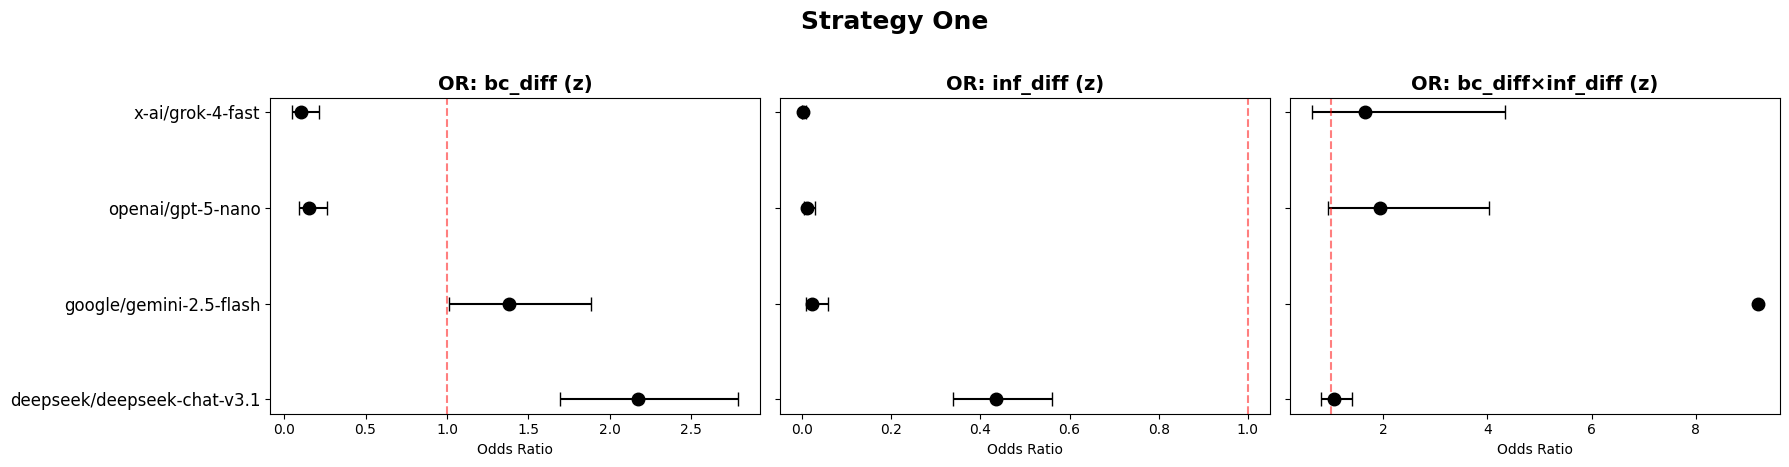

(                         Model     AUROC    N  OR_bc_diff_z  \
 0  deepseek/deepseek-chat-v3.1  0.772297  360      2.171050   
 1      google/gemini-2.5-flash  0.941798  359      1.381248   
 2            openai/gpt-5-nano  0.971972  360      0.152446   
 3             x-ai/grok-4-fast  0.984344  360      0.104670   
 
    OR_bc_diff_z_CI_low  OR_bc_diff_z_CI_high  OR_inf_diff_z  \
 0             1.691401              2.786720       0.435766   
 1             1.011432              1.886281       0.022218   
 2             0.089097              0.260837       0.010923   
 3             0.051552              0.212519       0.001921   
 
    OR_inf_diff_z_CI_low  OR_inf_diff_z_CI_high  OR_bc_x_inf_z  \
 0              0.338588               0.560835       1.055927   
 1              0.008417               0.058647       9.194806   
 2              0.004093               0.029148       1.931485   
 3              0.000418               0.008841       1.653739   
 
    OR_bc_x_inf_z_CI_low

In [6]:
run_dce_logit_zscore_interaction_with_auroc(full_results_df, strategy="strategy_one")

### Strategy Two Analysis (Political Orientation)

Prepared 4315 valid choice tasks for strategy=strategy_two.

Per-model ORs (3-way interaction set) + AUROC


,Model,AUROC,N,context_col,OR_inf_z,OR_inf_z_CI_low,OR_inf_z_CI_high,OR_bc_z,OR_bc_z_CI_low,OR_bc_z_CI_high,...,OR_inf_x_bc_CI_high,OR_inf_x_ctx,OR_inf_x_ctx_CI_low,OR_inf_x_ctx_CI_high,OR_bc_x_ctx,OR_bc_x_ctx_CI_low,OR_bc_x_ctx_CI_high,OR_inf_x_bc_x_ctx,OR_inf_x_bc_x_ctx_CI_low,OR_inf_x_bc_x_ctx_CI_high
0,deepseek/deepseek-chat-v3.1,0.728218,1080,capacity_context,0.503121,0.437270,0.578889,1.790996,1.560062,2.056114,...,1.166737,1.088185,0.945738,1.252089,1.000973,0.871910,1.149141,1.025558,0.881173,1.193601
1,google/gemini-2.5-flash,0.932919,1075,capacity_context,0.057909,0.040022,0.083791,1.610165,1.323371,1.959111,...,4.906820,0.946409,0.654627,1.368243,1.013242,0.832553,1.233146,1.105804,0.781925,1.563834
2,openai/gpt-5-nano,0.979524,1080,capacity_context,0.004105,0.001882,0.008953,0.105530,0.070740,0.157429,...,2.440663,2.719789,1.288045,5.743005,1.710806,1.162700,2.517292,1.355050,0.837538,2.192331
3,x-ai/grok-4-fast,0.990708,1080,capacity_context,0.000321,0.000083,0.001239,0.079882,0.048958,0.130341,...,5.248657,0.586219,0.154329,2.226761,0.879195,0.540485,1.430167,1.399018,0.625531,3.128947



Overall AUROC summary


,Strategy,context_col,Overall_AUROC_pooled,Macro_AUROC_mean_models,Weighted_AUROC_by_N,Total_N_pooled,Models_included
0,strategy_two,capacity_context,0.9521,0.907842,0.907813,4315,4


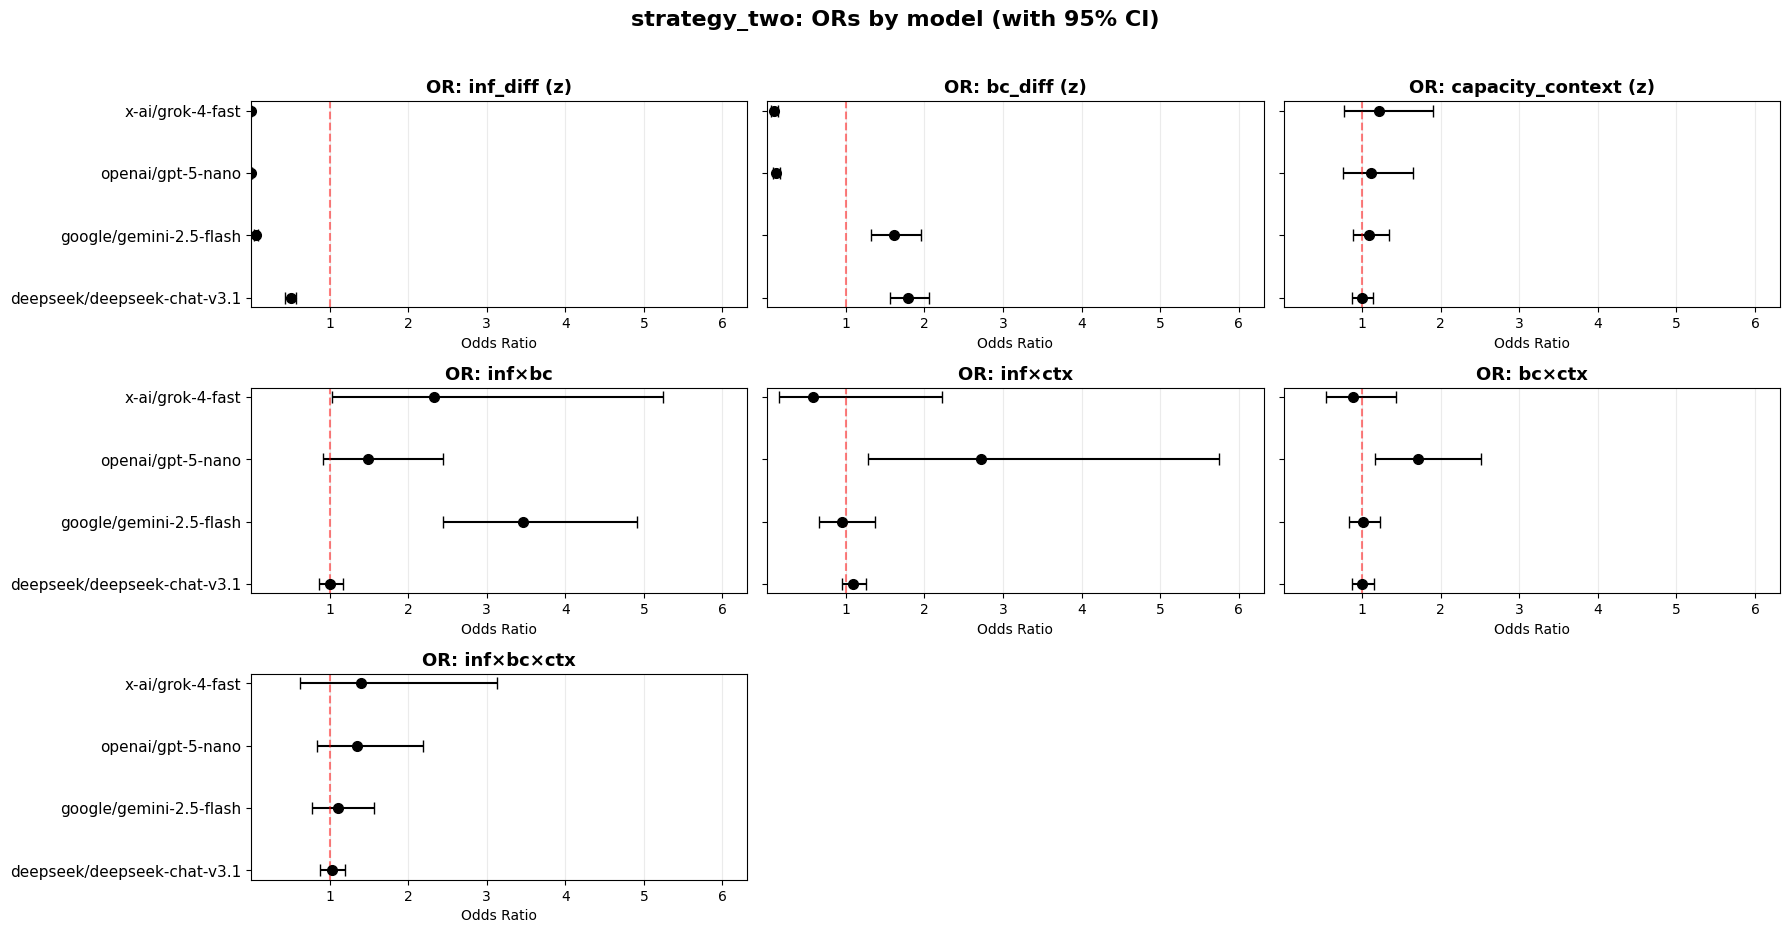

(                         Model     AUROC     N       context_col  OR_inf_z  \
 0  deepseek/deepseek-chat-v3.1  0.728218  1080  capacity_context  0.503121   
 1      google/gemini-2.5-flash  0.932919  1075  capacity_context  0.057909   
 2            openai/gpt-5-nano  0.979524  1080  capacity_context  0.004105   
 3             x-ai/grok-4-fast  0.990708  1080  capacity_context  0.000321   
 
    OR_inf_z_CI_low  OR_inf_z_CI_high   OR_bc_z  OR_bc_z_CI_low  \
 0         0.437270          0.578889  1.790996        1.560062   
 1         0.040022          0.083791  1.610165        1.323371   
 2         0.001882          0.008953  0.105530        0.070740   
 3         0.000083          0.001239  0.079882        0.048958   
 
    OR_bc_z_CI_high  ...  OR_inf_x_bc_CI_high  OR_inf_x_ctx  \
 0         2.056114  ...             1.166737      1.088185   
 1         1.959111  ...             4.906820      0.946409   
 2         0.157429  ...             2.440663      2.719789   
 3         0.1

In [7]:
run_dce_logit_zscore_context_3way_with_auroc(full_results_df, strategy="strategy_two", context_col="capacity_context")

### Strategy Four Analysis (User Preference)

In [8]:
def run_dce_logit_strategy_four(
    results_df,
    strategy="strategy_four",
    min_obs=10,
    plot=True,
    show_tables=True,
    plot_ncols=3
):
    """
    Specialized Logistic Regression for Strategy 4 (Dual Context + User Preference).
    Includes interactions between Attributes (Infection, NPI) and Contexts (Capacity, Economic, Preference).
    """
    import pandas as pd
    import numpy as np
    import statsmodels.api as sm
    import matplotlib.pyplot as plt
    from sklearn.metrics import roc_auc_score

    def show_df(df, title):
        if not show_tables: return
        print("\n" + "=" * 60 + "\n" + title + "\n" + "=" * 60)
        try:
            from IPython.display import display
            display(df)
        except: print(df.to_string())

    def np_zscore(series): 
        arr = np.asarray(series, dtype=float)
        mu, sigma = np.nanmean(arr), np.nanstd(arr, ddof=0)
        return pd.Series((arr - mu) / sigma if sigma > 0 else np.nan, index=series.index)

    df = results_df[results_df["strategy"] == strategy].copy()
    if df.empty:
        print(f"No data for {strategy}.")
        return pd.DataFrame(), pd.DataFrame()

    # Standardize columns
    num_cols = ["infection_rate_selected", "infection_rate_non_selected", "npi_level_selected", "npi_level_non_selected", "capacity_context", "economic_context", "user_preference_type_numeric"]
    for c in num_cols: df[c] = pd.to_numeric(df[c], errors="coerce")

    df["choice"] = (df["selected_choice"] == df["pair"].str.split("-").str[0]).astype(int)
    df["inf_diff"] = np.where(df["choice"] == 1, df["infection_rate_selected"] - df["infection_rate_non_selected"], df["infection_rate_non_selected"] - df["infection_rate_selected"])
    df["bc_diff"] = np.where(df["choice"] == 1, df["npi_level_selected"] - df["npi_level_non_selected"], df["npi_level_non_selected"] - df["npi_level_selected"])

    # Regression terms: main effects + key interactions
    terms = ["inf_diff_z", "bc_diff_z", "cap_z", "econ_z", "pref_z", 
             "cap_x_inf", "cap_x_bc", "econ_x_inf", "econ_x_bc", "pref_x_inf", "pref_x_bc"]

    per_model_rows = []
    for model_name in df["model"].dropna().unique():
        m_df = df[df["model"] == model_name].dropna(subset=["choice", "inf_diff", "bc_diff", "capacity_context", "economic_context", "user_preference_type_numeric"]).copy()
        if len(m_df) < min_obs: continue

        m_df["inf_diff_z"] = np_zscore(m_df["inf_diff"])
        m_df["bc_diff_z"] = np_zscore(m_df["bc_diff"])
        m_df["cap_z"] = np_zscore(m_df["capacity_context"])
        m_df["econ_z"] = np_zscore(m_df["economic_context"])
        m_df["pref_z"] = np_zscore(m_df["user_preference_type_numeric"])

        m_df["cap_x_inf"] = m_df["cap_z"] * m_df["inf_diff_z"]
        m_df["cap_x_bc"] = m_df["cap_z"] * m_df["bc_diff_z"]
        m_df["econ_x_inf"] = m_df["econ_z"] * m_df["inf_diff_z"]
        m_df["econ_x_bc"] = m_df["econ_z"] * m_df["bc_diff_z"]
        m_df["pref_x_inf"] = m_df["pref_z"] * m_df["inf_diff_z"]
        m_df["pref_x_bc"] = m_df["pref_z"] * m_df["bc_diff_z"]

        try:
            X = sm.add_constant(m_df[terms])
            y = m_df["choice"]
            res = sm.Logit(y, X).fit(disp=0)
            
            or_vals = np.exp(res.params)
            ci = np.exp(res.conf_int())
            auroc = roc_auc_score(y, res.predict(X))

            row = {"Model": model_name, "AUROC": auroc, "N": len(m_df)}
            for t in terms:
                row[f"OR_{t}"] = or_vals.get(t, np.nan)
                row[f"OR_{t}_low"] = ci.loc[t, 0] if t in ci.index else np.nan
                row[f"OR_{t}_high"] = ci.loc[t, 1] if t in ci.index else np.nan
            per_model_rows.append(row)
        except: continue

    per_model_df = pd.DataFrame(per_model_rows)
    show_df(per_model_df, f"{strategy} Analysis with Dual Context and User Preference")

    if plot and not per_model_df.empty:
        rows = (len(terms) // plot_ncols) + 1
        fig, axes = plt.subplots(rows, plot_ncols, figsize=(5*plot_ncols, 4*rows), sharey=True)
        axes = axes.flatten()
        for i, t in enumerate(terms):
            ax = axes[i]
            for idx, r in per_model_df.iterrows():
                ax.errorbar(r[f"OR_{t}"], idx, xerr=[[r[f"OR_{t}"]-r[f"OR_{t}_low"]],[r[f"OR_{t}_high"]-r[f"OR_{t}"]]], fmt='o', color='black')
            ax.axvline(1, color='red', linestyle='--')
            ax.set_title(f"OR: {t}")
            ax.set_yticks(range(len(per_model_df))); ax.set_yticklabels(per_model_df["Model"])
        for j in range(i+1, len(axes)): axes[j].set_visible(False)
        plt.tight_layout(); plt.show()

    return per_model_df, None


In [9]:
def run_dce_logit_strategy_four_ridge_cv(
    results_df,
    strategy="strategy_four",
    min_obs=10,
    plot=True,
    show_tables=True,
    plot_ncols=3,
    Cs=20,
    max_iter=5000
):
    """
    Ridge (L2) Logistic Regression for Strategy 4 with 10-fold CV.
    """
    from sklearn.linear_model import LogisticRegressionCV
    import pandas as pd
    import numpy as np
    import matplotlib.pyplot as plt
    from sklearn.metrics import roc_auc_score

    def np_zscore(series): 
        arr = np.asarray(series, dtype=float)
        mu, sigma = np.nanmean(arr), np.nanstd(arr, ddof=0)
        return pd.Series((arr - mu) / sigma if sigma > 0 else np.nan, index=series.index)

    df = results_df[results_df["strategy"] == strategy].copy()
    num_cols = ["infection_rate_selected", "infection_rate_non_selected", "npi_level_selected", "npi_level_non_selected", "capacity_context", "economic_context", "user_preference_type_numeric"]
    for c in num_cols: df[c] = pd.to_numeric(df[c], errors="coerce")
    df["choice"] = (df["selected_choice"] == df["pair"].str.split("-").str[0]).astype(int)
    df["inf_diff"] = np.where(df["choice"] == 1, df["infection_rate_selected"] - df["infection_rate_non_selected"], df["infection_rate_non_selected"] - df["infection_rate_selected"])
    df["bc_diff"] = np.where(df["choice"] == 1, df["npi_level_selected"] - df["npi_level_non_selected"], df["npi_level_non_selected"] - df["npi_level_selected"])

    terms = ["inf_diff_z", "bc_diff_z", "cap_z", "econ_z", "pref_z", 
             "cap_x_inf", "cap_x_bc", "econ_x_inf", "econ_x_bc", "pref_x_inf", "pref_x_bc"]

    per_model_rows = []
    for model_name in df["model"].dropna().unique():
        m_df = df[df["model"] == model_name].dropna(subset=["choice", "inf_diff", "bc_diff", "capacity_context", "economic_context", "user_preference_type_numeric"]).copy()
        if len(m_df) < min_obs: continue

        m_df["inf_diff_z"] = np_zscore(m_df["inf_diff"])
        m_df["bc_diff_z"] = np_zscore(m_df["bc_diff"])
        m_df["cap_z"] = np_zscore(m_df["capacity_context"])
        m_df["econ_z"] = np_zscore(m_df["economic_context"])
        m_df["pref_z"] = np_zscore(m_df["user_preference_type_numeric"])

        m_df["cap_x_inf"] = m_df["cap_z"] * m_df["inf_diff_z"]
        m_df["cap_x_bc"] = m_df["cap_z"] * m_df["bc_diff_z"]
        m_df["econ_x_inf"] = m_df["econ_z"] * m_df["inf_diff_z"]
        m_df["econ_x_bc"] = m_df["econ_z"] * m_df["bc_diff_z"]
        m_df["pref_x_inf"] = m_df["pref_z"] * m_df["inf_diff_z"]
        m_df["pref_x_bc"] = m_df["pref_z"] * m_df["bc_diff_z"]

        try:
            X = m_df[terms]
            y = m_df["choice"]
            clf = LogisticRegressionCV(Cs=Cs, cv=10, penalty='l2', max_iter=max_iter).fit(X, y)
            
            or_vals = np.exp(clf.coef_[0])
            auroc = roc_auc_score(y, clf.predict_proba(X)[:, 1])

            row = {"Model": model_name, "AUROC": auroc, "N": len(m_df)}
            for i, t in enumerate(terms):
                row[f"OR_{t}"] = or_vals[i]
            per_model_rows.append(row)
        except: continue

    per_model_df = pd.DataFrame(per_model_rows)
    if show_tables: print("\nStrategy 4 Ridge Results:\n", per_model_df)
    return per_model_df


In [10]:
run_dce_logit_strategy_four(full_results_df, strategy="strategy_four")



strategy_four Analysis with Dual Context and User Preference


""


(Empty DataFrame
 Columns: []
 Index: [],
 None)

In [11]:
run_dce_logit_strategy_four_ridge_cv(full_results_df, strategy="strategy_four")



Strategy 4 Ridge Results:
 Empty DataFrame
Columns: []
Index: []


""


### Strategy 3 Analysis

#### Default Logistic

In [12]:
def run_dce_logit_strategy_three(
    results_df,
    strategy="strategy_three",
    min_obs=10,
    plot=True,
    show_tables=True,
    plot_ncols=3
):
    """
    Specialized Logistic Regression for Strategy 3 (Dual Context: Capacity & Economic).
    Includes full set of requested main effects and interactions (up to 4-way).
    """
    import pandas as pd
    import numpy as np
    import statsmodels.api as sm
    import matplotlib.pyplot as plt
    from sklearn.metrics import roc_auc_score

    # --- Robust display/printing ---
    def show_df(df, title):
        if not show_tables:
            return
        print("\n" + "=" * 60)
        print(title)
        print("=" * 60)
        try:
            from IPython.display import display
            display(df)
        except Exception:
            print(df.to_string(index=False))

    # --- Helper: NumPy z-score ---
    def np_zscore(series: pd.Series) -> pd.Series:
        arr = np.asarray(series, dtype=float)
        mu = np.nanmean(arr)
        sigma = np.nanstd(arr, ddof=0)
        if (not np.isfinite(sigma)) or sigma == 0:
            return pd.Series(np.full_like(arr, np.nan, dtype=float), index=series.index)
        return pd.Series((arr - mu) / sigma, index=series.index)

    # --- 1. Filter strategy ---
    df = results_df[results_df["strategy"] == strategy].copy()
    print(f"Processing {strategy}: {len(df)} rows found.")

    if len(df) == 0:
        print("No data found for Strategy 3.")
        return pd.DataFrame(), pd.DataFrame()

    # --- 2. Ensure numeric cols ---
    num_cols = [
        "infection_rate_selected", "infection_rate_non_selected",
        "npi_level_selected", "npi_level_non_selected",
        "capacity_context", "economic_context"
    ]
    for c in num_cols:
        if c in df.columns:
            df[c] = pd.to_numeric(df[c], errors="coerce")
        else:
            print(f"Warning: Column {c} missing!")

    # --- 3. Choice & Attributes ---
    df["choice"] = (df["selected_choice"] == df["pair"].str.split("-").str[0]).astype(int)
    df["inf_1"] = np.where(df["choice"] == 1, df["infection_rate_selected"], df["infection_rate_non_selected"])
    df["inf_2"] = np.where(df["choice"] == 1, df["infection_rate_non_selected"], df["infection_rate_selected"])
    df["npi_1"] = np.where(df["choice"] == 1, df["npi_level_selected"], df["npi_level_non_selected"])
    df["npi_2"] = np.where(df["choice"] == 1, df["npi_level_non_selected"], df["npi_level_selected"])

    df["bc_diff"] = df["npi_1"] - df["npi_2"]
    df["inf_diff"] = df["inf_1"] - df["inf_2"]

    # --- 4. Regression Terms Definition ---
    # Terms reflect the requirements: cap, econ, inf, bc, and all layers of interactions
    terms = [
        "cap_z", "econ_z", "inf_diff_z", "bc_diff_z",
        "cap_x_econ", "cap_x_inf", "cap_x_bc", "econ_x_inf", "econ_x_bc", "inf_x_bc",
        "cap_x_econ_x_inf", "cap_x_econ_x_bc", "cap_x_inf_x_bc", "econ_x_inf_x_bc",
        "cap_x_econ_x_inf_x_bc"
    ]

    per_model_rows = []
    pooled_y, pooled_score = [], []

    for model_name in df["model"].dropna().unique():
        m_df = df[df["model"] == model_name].copy()
        m_df = m_df.dropna(subset=["choice", "bc_diff", "inf_diff", "capacity_context", "economic_context"])

        if len(m_df) < min_obs:
            continue

        # Standardize - Using naming consistent with earlier parts of the notebook
        m_df["inf_diff_z"] = np_zscore(m_df["inf_diff"])
        m_df["bc_diff_z"] = np_zscore(m_df["bc_diff"])
        m_df["cap_z"] = np_zscore(m_df["capacity_context"])
        m_df["econ_z"] = np_zscore(m_df["economic_context"])

        # 2-way Interactions
        m_df["cap_x_econ"] = m_df["cap_z"] * m_df["econ_z"]
        m_df["cap_x_inf"] = m_df["cap_z"] * m_df["inf_diff_z"]
        m_df["cap_x_bc"] = m_df["cap_z"] * m_df["bc_diff_z"]
        m_df["econ_x_inf"] = m_df["econ_z"] * m_df["inf_diff_z"]
        m_df["econ_x_bc"] = m_df["econ_z"] * m_df["bc_diff_z"]
        m_df["inf_x_bc"] = m_df["inf_diff_z"] * m_df["bc_diff_z"]

        # 3-way Interactions
        m_df["cap_x_econ_x_inf"] = m_df["cap_x_econ"] * m_df["inf_diff_z"]
        m_df["cap_x_econ_x_bc"] = m_df["cap_x_econ"] * m_df["bc_diff_z"]
        m_df["cap_x_inf_x_bc"] = m_df["cap_x_inf"] * m_df["bc_diff_z"]
        m_df["econ_x_inf_x_bc"] = m_df["econ_x_inf"] * m_df["bc_diff_z"]

        # 4-way Interaction
        m_df["cap_x_econ_x_inf_x_bc"] = m_df["cap_x_econ_x_inf"] * m_df["bc_diff_z"]

        # Fit Model
        try:
            X = sm.add_constant(m_df[terms])
            y = m_df["choice"]
            
            if y.nunique() < 2: continue

            res = sm.Logit(y, X).fit(disp=0)
            
            # AUROC
            y_score = res.predict(X)
            auroc = roc_auc_score(y, y_score)
            pooled_y.extend(y)
            pooled_score.extend(y_score)

            # Params
            or_vals = np.exp(res.params)
            ci = np.exp(res.conf_int())

            row = {"Model": model_name, "AUROC": auroc, "N": len(m_df)}
            for t in terms:
                row[f"OR_{t}"] = or_vals.get(t, np.nan)
                if t in ci.index:
                    row[f"OR_{t}_low"] = ci.loc[t, 0]
                    row[f"OR_{t}_high"] = ci.loc[t, 1]
                else:
                    row[f"OR_{t}_low"] = np.nan
                    row[f"OR_{t}_high"] = np.nan
            
            per_model_rows.append(row)

        except Exception as e:
            print(f"Error fitting model for {model_name}: {e}")
            continue

    per_model_df = pd.DataFrame(per_model_rows)
    show_df(per_model_df, "Strategy 3: Full Interaction Logistic Regression Analysis")

    # --- Visualization ---
    if plot and not per_model_df.empty:
        # The full expected set of plot terms, including inf_diff and bc_diff main effects
        all_plot_terms = [
            "inf_diff_z", "bc_diff_z", "cap_z", "econ_z", 
            "cap_x_econ", "cap_x_inf", "cap_x_bc", "econ_x_inf", 
            "econ_x_bc", "inf_x_bc", "cap_x_econ_x_inf",
            "cap_x_econ_x_bc", "cap_x_inf_x_bc", "econ_x_inf_x_bc",
            "cap_x_econ_x_inf_x_bc"
        ]
        n_plots = len(all_plot_terms)
        cols = plot_ncols
        rows = (n_plots // cols) + (1 if n_plots % cols > 0 else 0)
        
        fig, axes = plt.subplots(rows, cols, figsize=(5*cols, 4*rows), sharey=True)
        axes = axes.flatten()

        for i, t in enumerate(all_plot_terms):
            ax = axes[i]
            
            if f"OR_{t}" not in per_model_df.columns: 
                ax.set_visible(False)
                continue
            
            # Plot points
            for idx, row in per_model_df.iterrows():
                or_val = row[f"OR_{t}"]
                low = row[f"OR_{t}_low"]
                high = row[f"OR_{t}_high"]
                
                if pd.isna(or_val): continue
                
                err_low = or_val - low if pd.notna(low) else 0
                err_high = high - or_val if pd.notna(high) else 0
                
                # Cap big errors for display sanity
                if err_high > 20: err_high = 20
                if err_low < -20: err_low = -20
                
                ax.errorbar(or_val, idx, xerr=[[err_low], [err_high]], fmt='o', color='black', capsize=5)

            ax.set_yticks(range(len(per_model_df)))
            ax.set_yticklabels(per_model_df["Model"])
            ax.axvline(1, color='red', linestyle='--', alpha=0.5)
            ax.set_title(f"OR: {t}", fontsize=12, fontweight='bold')
            ax.grid(True, axis='x', alpha=0.3)

        # Hide extra axes
        for i in range(n_plots, len(axes)):
            axes[i].set_visible(False)

        plt.tight_layout()
        plt.show()

    return per_model_df, None


Running Strategy 3 Analysis...
Processing strategy_three: 2590 rows found.

Strategy 3: Full Interaction Logistic Regression Analysis


,Model,AUROC,N,OR_cap_z,OR_cap_z_low,OR_cap_z_high,OR_econ_z,OR_econ_z_low,OR_econ_z_high,OR_inf_diff_z,...,OR_cap_x_econ_x_bc_high,OR_cap_x_inf_x_bc,OR_cap_x_inf_x_bc_low,OR_cap_x_inf_x_bc_high,OR_econ_x_inf_x_bc,OR_econ_x_inf_x_bc_low,OR_econ_x_inf_x_bc_high,OR_cap_x_econ_x_inf_x_bc,OR_cap_x_econ_x_inf_x_bc_low,OR_cap_x_econ_x_inf_x_bc_high
0,deepseek/deepseek-chat-v3.1,0.861580,648,1.009288,0.788664,1.291631,0.990224,0.774478,1.266070,0.281371,...,1.671033,1.036565,0.790822,1.358669,0.998360,0.762447,1.307267,0.892211,0.683967,1.163858
1,x-ai/grok-4-fast,0.969205,648,1.048422,0.743282,1.478832,1.010420,0.714927,1.428048,0.011892,...,1.478089,1.018186,0.559321,1.853502,0.976692,0.532736,1.790619,1.612003,0.905449,2.869905
2,openai/gpt-5-nano,0.994060,648,1.015407,0.479275,2.151272,0.671500,0.319461,1.411475,0.000113,...,2.317888,1.198075,0.412990,3.475583,0.636406,0.221496,1.828535,0.802852,0.279743,2.304155
3,google/gemini-2.5-flash,0.951902,646,0.790225,0.577395,1.081505,0.843641,0.616439,1.154583,0.015889,...,1.166051,1.130058,0.611786,2.087382,1.095488,0.590935,2.030841,1.664575,0.919385,3.013763


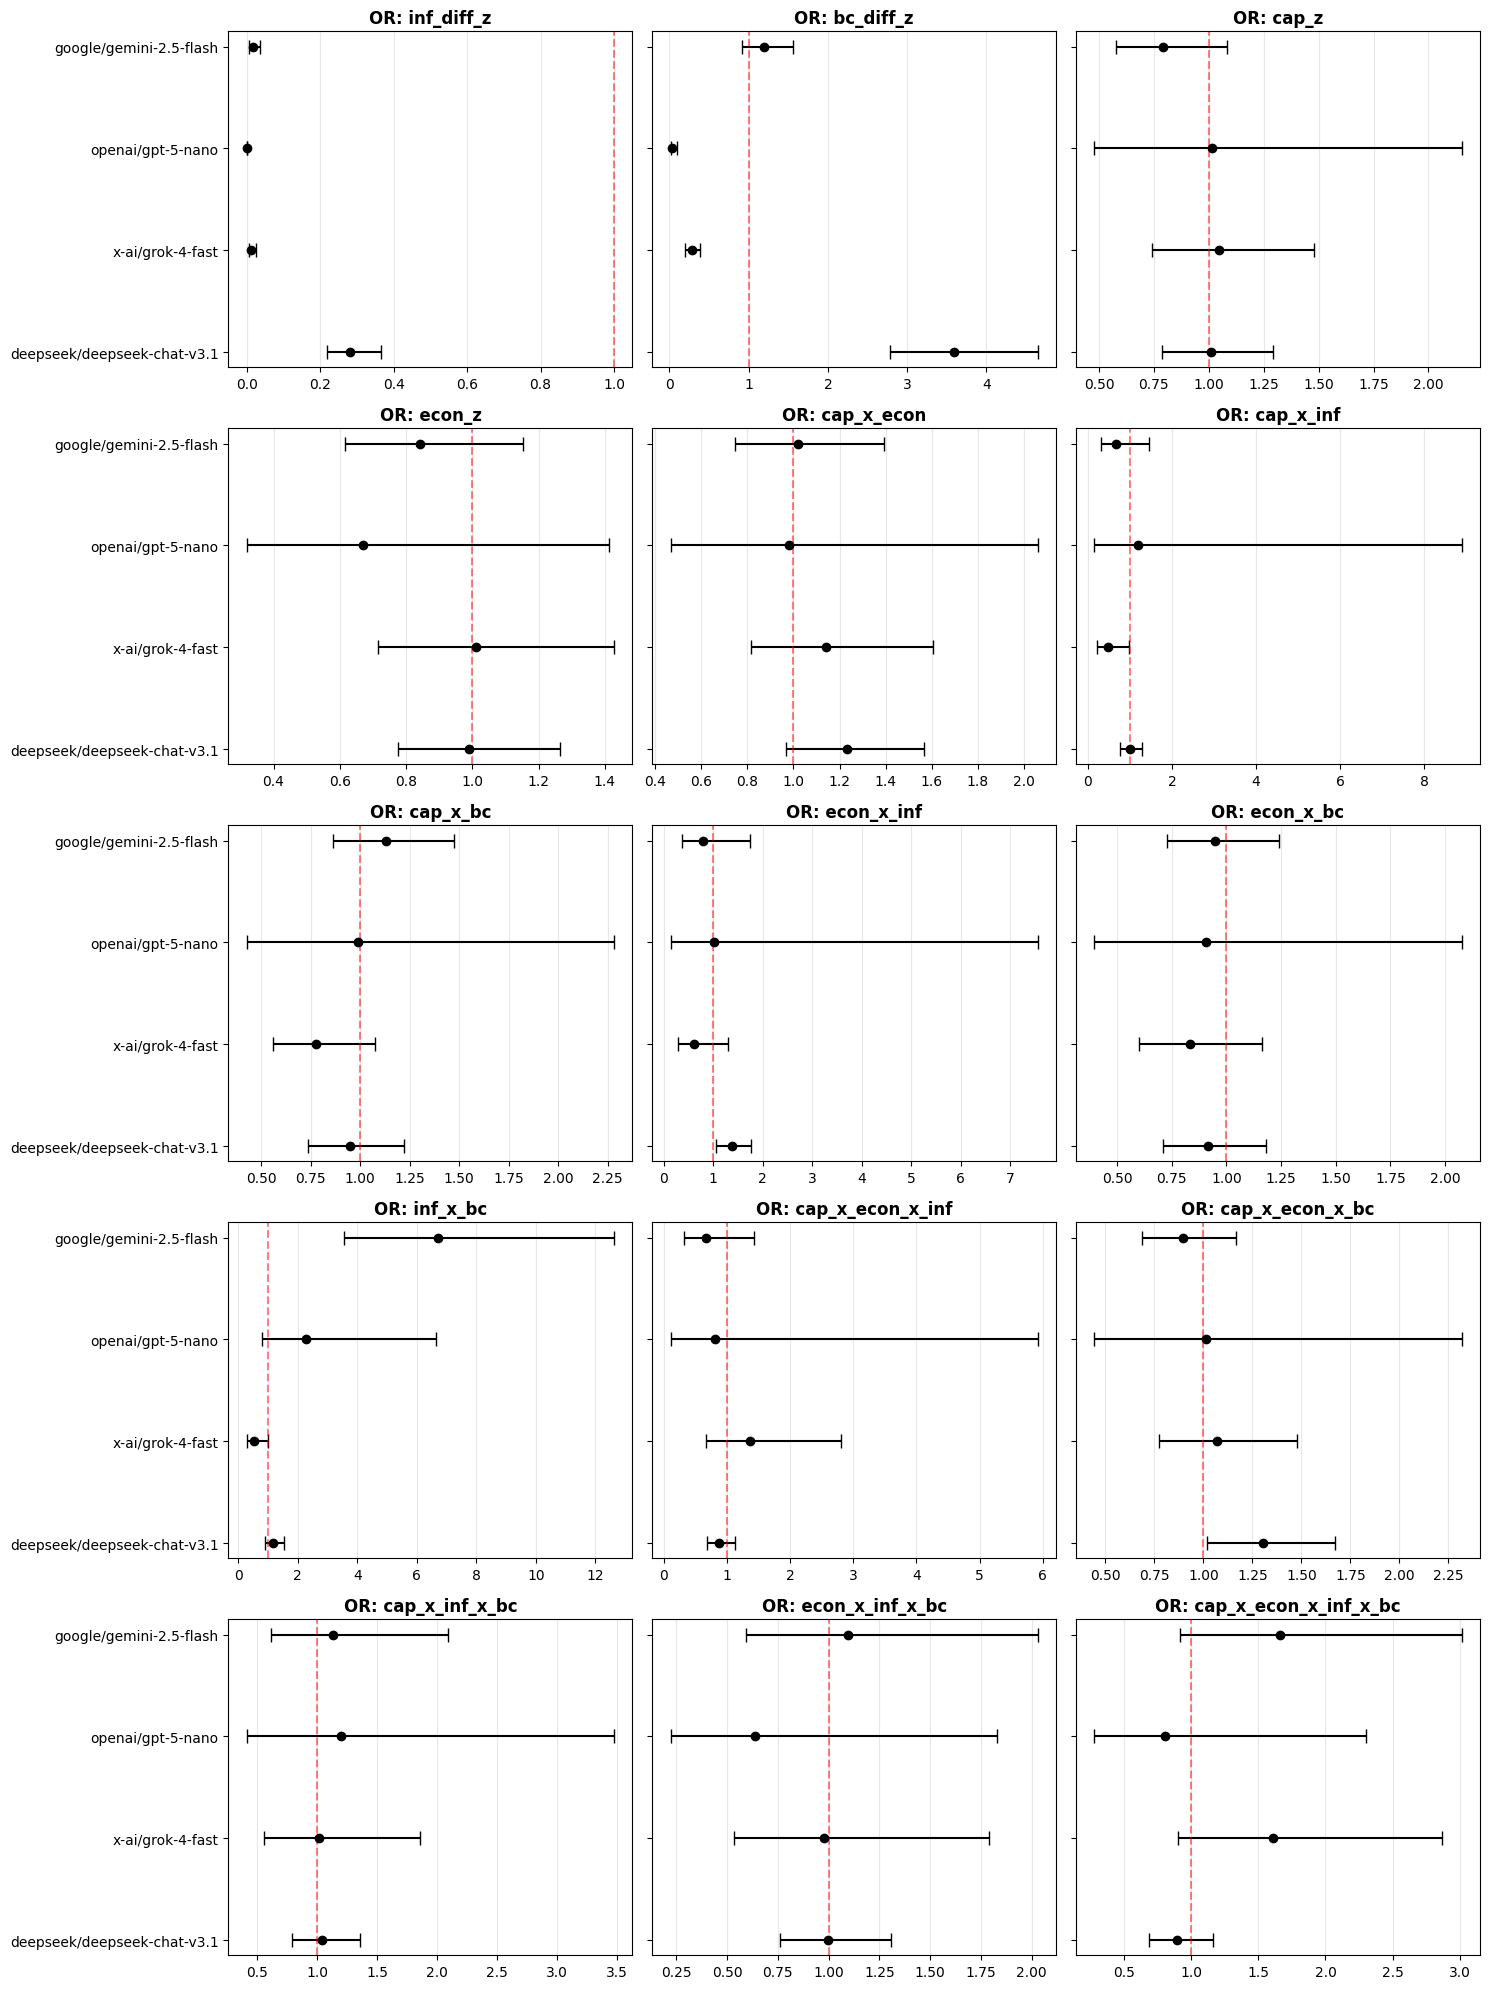

In [13]:
# Run Strategy 3 Analysis
if "strategy_three" in strategies and not full_results_df[full_results_df["strategy"]=="strategy_three"].empty:
    print("Running Strategy 3 Analysis...")
    run_dce_logit_strategy_three(full_results_df, strategy="strategy_three")
else:
    print("Strategy 3 data not loaded or empty.")

#### L2 / Ridge Regression

In [14]:
def run_dce_logit_strategy_three_ridge_cv(
    results_df,
    strategy="strategy_three",
    min_obs=10,
    plot=True,
    show_tables=True,
    plot_ncols=3,
    random_state=42,
    Cs=20,
    max_iter=5000,
    n_jobs=-1,
    # --- NEW: bootstrap options ---
    n_boot=1000, # was 300
    ci_level=0.95,
    bootstrap_refit_cv=False,   # False = bootstrap with best_C fixed (much faster)
    compute_auroc_ci=True
):
    """
    Ridge (L2) Logistic Regression for Strategy 3 (Dual Context: Capacity & Economic),
    with penalty parameter optimized via (up to) 10-fold CV (LogisticRegressionCV),
    plus bootstrap percentile confidence intervals for ORs.

    Notes on CIs:
      - Uses percentile bootstrap: CI = quantiles of bootstrap distribution
        (e.g., 2.5% and 97.5% for 95% CI). 
      - By default, bootstrap holds best_C fixed (conditional-on-selected-C intervals).
        Set bootstrap_refit_cv=True to re-run CV inside each bootstrap (very slow). 
    """
    import pandas as pd
    import numpy as np
    import matplotlib.pyplot as plt
    from sklearn.metrics import roc_auc_score
    from sklearn.linear_model import LogisticRegressionCV, LogisticRegression
    from sklearn.model_selection import StratifiedKFold

    # --- Robust display/printing ---
    def show_df(df, title):
        if not show_tables:
            return
        print("\n" + "=" * 60)
        print(title)
        print("=" * 60)
        try:
            from IPython.display import display
            display(df)
        except Exception:
            print(df.to_string(index=False))

    # --- Helper: NumPy z-score ---
    def np_zscore(series: pd.Series) -> pd.Series:
        arr = np.asarray(series, dtype=float)
        mu = np.nanmean(arr)
        sigma = np.nanstd(arr, ddof=0)
        if (not np.isfinite(sigma)) or sigma == 0:
            return pd.Series(np.full_like(arr, np.nan, dtype=float), index=series.index)
        return pd.Series((arr - mu) / sigma, index=series.index)

    # --- Feature engineering into the required "terms" ---
    terms = [
        "cap_z", "econ_z", "inf_diff_z", "bc_diff_z",
        "cap_x_econ", "cap_x_inf", "cap_x_bc", "econ_x_inf", "econ_x_bc", "inf_x_bc",
        "cap_x_econ_x_inf", "cap_x_econ_x_bc", "cap_x_inf_x_bc", "econ_x_inf_x_bc",
        "cap_x_econ_x_inf_x_bc"
    ]

    def build_design_matrix(m_df: pd.DataFrame) -> pd.DataFrame:
        m_df = m_df.copy()

        # Standardize
        m_df["inf_diff_z"] = np_zscore(m_df["inf_diff"])
        m_df["bc_diff_z"]  = np_zscore(m_df["bc_diff"])
        m_df["cap_z"]      = np_zscore(m_df["capacity_context"])
        m_df["econ_z"]     = np_zscore(m_df["economic_context"])

        # 2-way
        m_df["cap_x_econ"] = m_df["cap_z"] * m_df["econ_z"]
        m_df["cap_x_inf"]  = m_df["cap_z"] * m_df["inf_diff_z"]
        m_df["cap_x_bc"]   = m_df["cap_z"] * m_df["bc_diff_z"]
        m_df["econ_x_inf"] = m_df["econ_z"] * m_df["inf_diff_z"]
        m_df["econ_x_bc"]  = m_df["econ_z"] * m_df["bc_diff_z"]
        m_df["inf_x_bc"]   = m_df["inf_diff_z"] * m_df["bc_diff_z"]

        # 3-way
        m_df["cap_x_econ_x_inf"] = m_df["cap_x_econ"] * m_df["inf_diff_z"]
        m_df["cap_x_econ_x_bc"]  = m_df["cap_x_econ"] * m_df["bc_diff_z"]
        m_df["cap_x_inf_x_bc"]   = m_df["cap_x_inf"] * m_df["bc_diff_z"]
        m_df["econ_x_inf_x_bc"]  = m_df["econ_x_inf"] * m_df["bc_diff_z"]

        # 4-way
        m_df["cap_x_econ_x_inf_x_bc"] = m_df["cap_x_econ_x_inf"] * m_df["bc_diff_z"]

        m_df = m_df.dropna(subset=["choice"] + terms)
        return m_df

    # --- 1. Filter strategy ---
    df = results_df[results_df["strategy"] == strategy].copy()
    print(f"Processing {strategy}: {len(df)} rows found.")

    if len(df) == 0:
        print("No data found.")
        return pd.DataFrame(), pd.DataFrame()

    # --- 2. Ensure numeric cols ---
    num_cols = [
        "infection_rate_selected", "infection_rate_non_selected",
        "npi_level_selected", "npi_level_non_selected",
        "capacity_context", "economic_context"
    ]
    for c in num_cols:
        if c in df.columns:
            df[c] = pd.to_numeric(df[c], errors="coerce")
        else:
            print(f"Warning: Column {c} missing!")

    # --- 3. Choice & Attributes ---
    df["choice"] = (df["selected_choice"] == df["pair"].str.split("-").str[0]).astype(int)
    df["inf_1"] = np.where(df["choice"] == 1, df["infection_rate_selected"], df["infection_rate_non_selected"])
    df["inf_2"] = np.where(df["choice"] == 1, df["infection_rate_non_selected"], df["infection_rate_selected"])
    df["npi_1"] = np.where(df["choice"] == 1, df["npi_level_selected"], df["npi_level_non_selected"])
    df["npi_2"] = np.where(df["choice"] == 1, df["npi_level_non_selected"], df["npi_level_selected"])
    df["bc_diff"] = df["npi_1"] - df["npi_2"]
    df["inf_diff"] = df["inf_1"] - df["inf_2"]

    per_model_rows = []
    pooled_y_fit, pooled_score_fit = [], []

    rng = np.random.default_rng(random_state)
    alpha = 1.0 - float(ci_level)
    q_low, q_high = 100 * (alpha / 2.0), 100 * (1.0 - alpha / 2.0)

    # --- 4. Fit per model (ridge CV) + bootstrap CIs ---
    for model_name in df["model"].dropna().unique():
        base_df = df[df["model"] == model_name].copy()
        base_df = base_df.dropna(subset=["choice", "bc_diff", "inf_diff", "capacity_context", "economic_context"])
        if len(base_df) < min_obs:
            continue

        base_df = build_design_matrix(base_df)
        if len(base_df) < min_obs:
            continue

        X = base_df[terms].to_numpy(dtype=float)
        y = base_df["choice"].to_numpy(dtype=int)

        vals, counts = np.unique(y, return_counts=True)
        if len(vals) < 2:
            continue

        min_class = int(np.min(counts))
        if min_class < 2:
            continue
        n_splits = int(min(10, min_class))
        cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=random_state)

        try:
            # --- CV to choose C, then refit on full data [web:123]
            clf_cv = LogisticRegressionCV(
                Cs=Cs,
                cv=cv,
                penalty="l2",
                solver="lbfgs",
                scoring="roc_auc",
                max_iter=max_iter,
                n_jobs=n_jobs,
                refit=True,
                fit_intercept=True
            )
            clf_cv.fit(X, y)

            scores_dict = clf_cv.scores_
            key = 1 if 1 in scores_dict else list(scores_dict.keys())[0]
            scores = scores_dict[key]  # (n_folds, n_Cs)
            mean_cv_auc_by_C = scores.mean(axis=0)
            cv_auc_best = float(np.max(mean_cv_auc_by_C))

            best_C = float(np.ravel(clf_cv.C_)[0]) if hasattr(clf_cv, "C_") else np.nan

            # Fit AUROC on training set probabilities
            y_score_fit = clf_cv.predict_proba(X)[:, 1]
            auroc_fit = float(roc_auc_score(y, y_score_fit))

            pooled_y_fit.append(y)
            pooled_score_fit.append(y_score_fit)

            # Point-estimate coefficients and ORs
            beta_hat = clf_cv.coef_.ravel()
            or_hat = np.exp(beta_hat)

            # --- Bootstrap distributions (betas, and optionally AUROC) ---
            boot_betas = []
            boot_aurocs = []

            n = len(base_df)
            for b in range(int(n_boot)):
                idx = rng.integers(0, n, size=n)
                b_df = base_df.iloc[idx].copy()

                # IMPORTANT: recompute z-scores + interactions within the bootstrap sample
                # (so the whole feature pipeline is resampled)
                b_raw = df[df["model"] == model_name].copy()
                b_raw = b_raw.dropna(subset=["choice", "bc_diff", "inf_diff", "capacity_context", "economic_context"])
                # align resampling to raw rows by sampling from base_df's index positions:
                # easiest is to reconstruct from base_df directly by keeping needed source cols
                # base_df already contains inf_diff, bc_diff, contexts, and choice
                # we can compute z-scores/interactions from base_df bootstrap sample:
                b_df = build_design_matrix(b_df)

                if len(b_df) < min_obs:
                    continue

                Xb = b_df[terms].to_numpy(dtype=float)
                yb = b_df["choice"].to_numpy(dtype=int)
                if pd.Series(yb).nunique(dropna=True) < 2:
                    continue

                try:
                    if bootstrap_refit_cv:
                        # Very slow: run CV inside each bootstrap [web:123]
                        vals_b, counts_b = np.unique(yb, return_counts=True)
                        if len(vals_b) < 2:
                            continue
                        min_class_b = int(np.min(counts_b))
                        if min_class_b < 2:
                            continue
                        n_splits_b = int(min(10, min_class_b))
                        cv_b = StratifiedKFold(n_splits=n_splits_b, shuffle=True, random_state=random_state + b)

                        clf_b = LogisticRegressionCV(
                            Cs=Cs,
                            cv=cv_b,
                            penalty="l2",
                            solver="lbfgs",
                            scoring="roc_auc",
                            max_iter=max_iter,
                            n_jobs=n_jobs,
                            refit=True,
                            fit_intercept=True
                        )
                        clf_b.fit(Xb, yb)
                        beta_b = clf_b.coef_.ravel()
                        score_b = clf_b.predict_proba(Xb)[:, 1]
                    else:
                        # Fast: hold best_C fixed, refit ridge logistic
                        clf_b = LogisticRegression(
                            C=best_C,
                            penalty="l2",
                            solver="lbfgs",
                            max_iter=max_iter,
                            fit_intercept=True
                        )
                        clf_b.fit(Xb, yb)
                        beta_b = clf_b.coef_.ravel()
                        score_b = clf_b.predict_proba(Xb)[:, 1]

                    boot_betas.append(beta_b)

                    if compute_auroc_ci:
                        boot_aurocs.append(float(roc_auc_score(yb, score_b)))

                except Exception:
                    continue

            boot_betas = np.asarray(boot_betas, dtype=float)
            boot_aurocs = np.asarray(boot_aurocs, dtype=float) if compute_auroc_ci else None

            # If too few bootstrap successes, CI stays NaN
            ci_ok = boot_betas.shape[0] >= max(30, int(0.2 * n_boot))

            row = {
                "Model": model_name,
                "N": int(len(base_df)),
                "best_C": best_C,
                "AUROC_CV_best": cv_auc_best,
                "AUROC_fit": auroc_fit,
                "n_boot_success": int(boot_betas.shape[0]),
            }

            if compute_auroc_ci and (boot_aurocs is not None) and (boot_aurocs.size >= 30):
                row["AUROC_fit_CI_low"] = float(np.nanpercentile(boot_aurocs, q_low))
                row["AUROC_fit_CI_high"] = float(np.nanpercentile(boot_aurocs, q_high))
            else:
                row["AUROC_fit_CI_low"] = np.nan
                row["AUROC_fit_CI_high"] = np.nan

            # OR CIs via percentile bootstrap on beta, then exp (monotone transform)
            for j, t in enumerate(terms):
                row[f"OR_{t}"] = float(or_hat[j])
                if ci_ok:
                    beta_low = float(np.nanpercentile(boot_betas[:, j], q_low))
                    beta_high = float(np.nanpercentile(boot_betas[:, j], q_high))
                    row[f"OR_{t}_low"] = float(np.exp(beta_low))
                    row[f"OR_{t}_high"] = float(np.exp(beta_high))
                else:
                    row[f"OR_{t}_low"] = np.nan
                    row[f"OR_{t}_high"] = np.nan

            per_model_rows.append(row)

        except Exception as e:
            print(f"Error fitting ridge-CV model for {model_name}: {e}")
            continue

    per_model_df = pd.DataFrame(per_model_rows).sort_values("Model").reset_index(drop=True)
    show_df(per_model_df, "Strategy 3: Ridge (L2) + 10-fold CV + Bootstrap OR CIs")

    # --- Overall / pooled summary ---
    overall_fit_auroc = np.nan
    total_n = int(per_model_df["N"].sum()) if not per_model_df.empty else 0
    if len(pooled_y_fit) > 0:
        y_all = np.concatenate(pooled_y_fit)
        s_all = np.concatenate(pooled_score_fit)
        if pd.Series(y_all).nunique(dropna=True) == 2:
            overall_fit_auroc = float(roc_auc_score(y_all, s_all))

    macro_cv = float(per_model_df["AUROC_CV_best"].mean()) if not per_model_df.empty else np.nan
    weighted_cv = np.nan
    if not per_model_df.empty:
        w = per_model_df["N"].astype(float)
        if w.sum() > 0:
            weighted_cv = float((per_model_df["AUROC_CV_best"] * w).sum() / w.sum())

    overall_df = pd.DataFrame([{
        "Strategy": strategy,
        "Models_included": int(per_model_df["Model"].nunique()) if not per_model_df.empty else 0,
        "Total_N": total_n,
        "Overall_AUROC_fit_pooled": overall_fit_auroc,
        "Macro_AUROC_CV_best": macro_cv,
        "Weighted_AUROC_CV_best_by_N": weighted_cv
    }])
    show_df(overall_df, "Overall AUROC summary (Strategy 3)")

    # --- Visualization: OR plots WITH bootstrap CIs ---
    if plot and not per_model_df.empty:
        all_plot_terms = [
            "inf_diff_z", "bc_diff_z", "cap_z", "econ_z",
            "cap_x_econ", "cap_x_inf", "cap_x_bc", "econ_x_inf",
            "econ_x_bc", "inf_x_bc", "cap_x_econ_x_inf",
            "cap_x_econ_x_bc", "cap_x_inf_x_bc", "econ_x_inf_x_bc",
            "cap_x_econ_x_inf_x_bc"
        ]

        n_plots = len(all_plot_terms)
        cols = int(plot_ncols)
        rows = int(np.ceil(n_plots / cols))

        fig, axes = plt.subplots(rows, cols, figsize=(5 * cols, 4 * rows), sharey=True)
        axes = np.array(axes).flatten()

        for i, t in enumerate(all_plot_terms):
            ax = axes[i]
            col = f"OR_{t}"
            lo_col = f"OR_{t}_low"
            hi_col = f"OR_{t}_high"
            if col not in per_model_df.columns:
                ax.set_visible(False)
                continue

            for idx, r in per_model_df.iterrows():
                or_val = r[col]
                lo = r.get(lo_col, np.nan)
                hi = r.get(hi_col, np.nan)

                if pd.isna(or_val):
                    continue

                if pd.notna(lo) and pd.notna(hi):
                    left_err = max(0.0, or_val - lo)
                    right_err = max(0.0, hi - or_val)
                    ax.errorbar(
                        or_val, idx,
                        xerr=[[left_err], [right_err]],
                        fmt="o",
                        color="black",
                        ecolor="black",
                        capsize=5
                    )
                else:
                    ax.plot(or_val, idx, "o", color="black", markersize=7)

            ax.set_yticks(range(len(per_model_df)))
            ax.set_yticklabels(per_model_df["Model"])
            ax.axvline(1, color="red", linestyle="--", alpha=0.5)
            ax.set_title(f"OR: {t}", fontsize=12, fontweight="bold")
            ax.grid(True, axis="x", alpha=0.3)

        for j in range(n_plots, len(axes)):
            axes[j].set_visible(False)

        plt.tight_layout()
        plt.show()

    return per_model_df, overall_df


Processing strategy_three: 2590 rows found.

Strategy 3: Ridge (L2) + 10-fold CV + Bootstrap OR CIs


,Model,N,best_C,AUROC_CV_best,AUROC_fit,n_boot_success,AUROC_fit_CI_low,AUROC_fit_CI_high,OR_cap_z,OR_cap_z_low,...,OR_cap_x_econ_x_bc_high,OR_cap_x_inf_x_bc,OR_cap_x_inf_x_bc_low,OR_cap_x_inf_x_bc_high,OR_econ_x_inf_x_bc,OR_econ_x_inf_x_bc_low,OR_econ_x_inf_x_bc_high,OR_cap_x_econ_x_inf_x_bc,OR_cap_x_econ_x_inf_x_bc_low,OR_cap_x_econ_x_inf_x_bc_high
0,deepseek/deepseek-chat-v3.1,648,0.004833,0.843955,0.858209,1000,0.831090,0.891962,1.010708,0.950222,...,1.100677,1.003643,0.954756,1.059122,0.996922,0.942106,1.048537,0.995152,0.947343,1.052228
1,google/gemini-2.5-flash,646,1.623777,0.946279,0.951522,1000,0.941092,0.969511,0.798181,0.585317,...,1.156068,1.022442,0.630272,1.492962,1.015874,0.660021,1.468271,1.480084,0.924959,2.114945
2,openai/gpt-5-nano,648,0.088587,0.993655,0.993898,1000,0.986643,1.000000,0.993486,0.888222,...,1.150218,1.036782,0.894473,1.199781,0.963354,0.796301,1.161281,0.956745,0.827002,1.105362
3,x-ai/grok-4-fast,648,4.281332,0.964400,0.969057,1000,0.956468,0.987286,1.049042,0.662059,...,1.584170,1.028522,0.282617,3.230608,0.973608,0.497245,2.412157,1.558099,0.685004,3.166568



Overall AUROC summary (Strategy 3)


,Strategy,Models_included,Total_N,Overall_AUROC_fit_pooled,Macro_AUROC_CV_best,Weighted_AUROC_CV_best_by_N
0,strategy_three,4,2590,0.959094,0.937072,0.937065


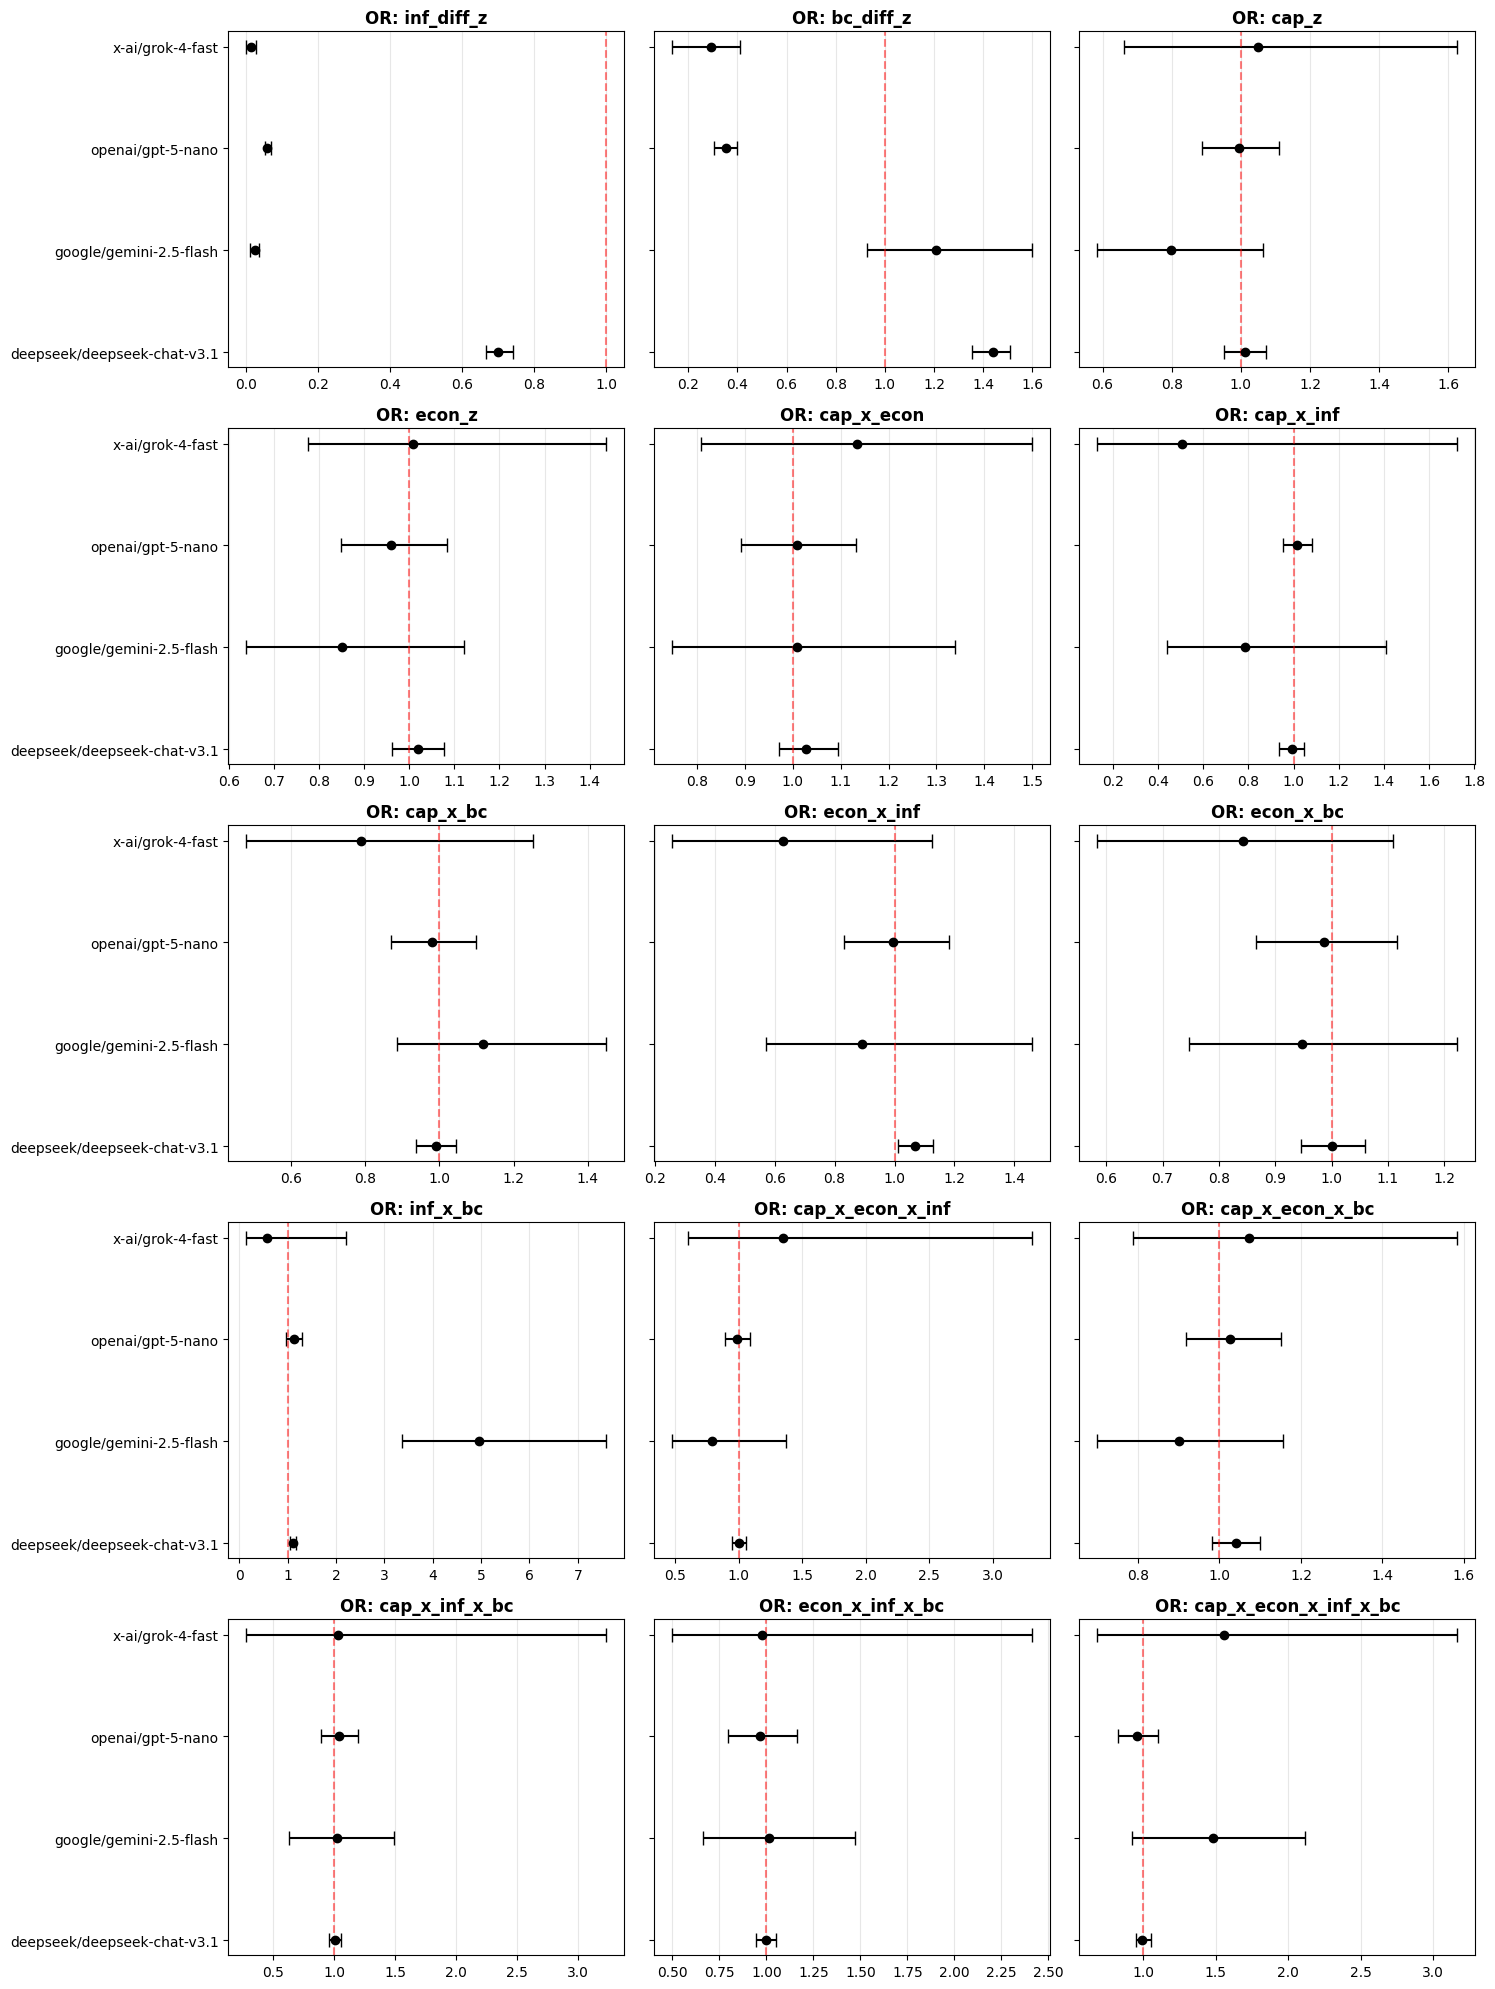

(                         Model    N    best_C  AUROC_CV_best  AUROC_fit  \
 0  deepseek/deepseek-chat-v3.1  648  0.004833       0.843955   0.858209   
 1      google/gemini-2.5-flash  646  1.623777       0.946279   0.951522   
 2            openai/gpt-5-nano  648  0.088587       0.993655   0.993898   
 3             x-ai/grok-4-fast  648  4.281332       0.964400   0.969057   
 
    n_boot_success  AUROC_fit_CI_low  AUROC_fit_CI_high  OR_cap_z  \
 0            1000          0.831090           0.891962  1.010708   
 1            1000          0.941092           0.969511  0.798181   
 2            1000          0.986643           1.000000  0.993486   
 3            1000          0.956468           0.987286  1.049042   
 
    OR_cap_z_low  ...  OR_cap_x_econ_x_bc_high  OR_cap_x_inf_x_bc  \
 0      0.950222  ...                 1.100677           1.003643   
 1      0.585317  ...                 1.156068           1.022442   
 2      0.888222  ...                 1.150218           1.03678

In [15]:
run_dce_logit_strategy_three_ridge_cv(full_results_df, strategy="strategy_three")


#### Elastic Regression

In [16]:
def run_dce_logit_strategy_three_elasticnet_cv(
    results_df = full_results_df,
    strategy="strategy_three",
    min_obs=10,
    plot=True,
    show_tables=True,
    plot_ncols=3,
    random_state=42,
    Cs=20,                    # int or array; LogisticRegressionCV accepts both [web:123]
    l1_ratios=(0.1, 0.5, 0.9), # must be provided for elasticnet in LogisticRegressionCV [web:123]
    max_iter=10000,
    n_jobs=-1
):
    """
    Elastic-Net Logistic Regression for Strategy 3 (Dual Context: Capacity & Economic),
    tuning C and l1_ratio via CV (default CV=5 in sklearn unless you pass a CV splitter). [web:123]

    Returns:
      - per_model_df: ORs (exp(coef)), best_C, best_l1_ratio, CV AUROC, fit AUROC, N
      - overall_df: pooled fit AUROC, macro/weighted summaries of per-model CV AUROC
    """
    import pandas as pd
    import numpy as np
    import matplotlib.pyplot as plt
    from sklearn.metrics import roc_auc_score
    from sklearn.linear_model import LogisticRegressionCV

    # --- Robust display/printing ---
    def show_df(df, title):
        if not show_tables:
            return
        print("\n" + "=" * 60)
        print(title)
        print("=" * 60)
        try:
            from IPython.display import display
            display(df)
        except Exception:
            print(df.to_string(index=False))

    # --- Helper: NumPy z-score ---
    def np_zscore(series: pd.Series) -> pd.Series:
        arr = np.asarray(series, dtype=float)
        mu = np.nanmean(arr)
        sigma = np.nanstd(arr, ddof=0)
        if (not np.isfinite(sigma)) or sigma == 0:
            return pd.Series(np.full_like(arr, np.nan, dtype=float), index=series.index)
        return pd.Series((arr - mu) / sigma, index=series.index)

    # --- 1. Filter strategy ---
    df = results_df[results_df["strategy"] == strategy].copy()
    print(f"Processing {strategy}: {len(df)} rows found.")
    if len(df) == 0:
        print("No data found for Strategy 3.")
        return pd.DataFrame(), pd.DataFrame()

    # --- 2. Ensure numeric cols ---
    num_cols = [
        "infection_rate_selected", "infection_rate_non_selected",
        "npi_level_selected", "npi_level_non_selected",
        "capacity_context", "economic_context"
    ]
    for c in num_cols:
        if c in df.columns:
            df[c] = pd.to_numeric(df[c], errors="coerce")
        else:
            print(f"Warning: Column {c} missing!")

    # --- 3. Choice & Attributes ---
    df["choice"] = (df["selected_choice"] == df["pair"].str.split("-").str[0]).astype(int)
    df["inf_1"] = np.where(df["choice"] == 1, df["infection_rate_selected"], df["infection_rate_non_selected"])
    df["inf_2"] = np.where(df["choice"] == 1, df["infection_rate_non_selected"], df["infection_rate_selected"])
    df["npi_1"] = np.where(df["choice"] == 1, df["npi_level_selected"], df["npi_level_non_selected"])
    df["npi_2"] = np.where(df["choice"] == 1, df["npi_level_non_selected"], df["npi_level_selected"])
    df["bc_diff"] = df["npi_1"] - df["npi_2"]
    df["inf_diff"] = df["inf_1"] - df["inf_2"]

    # --- 4. Terms ---
    terms = [
        "cap_z", "econ_z", "inf_diff_z", "bc_diff_z",
        "cap_x_econ", "cap_x_inf", "cap_x_bc", "econ_x_inf", "econ_x_bc", "inf_x_bc",
        "cap_x_econ_x_inf", "cap_x_econ_x_bc", "cap_x_inf_x_bc", "econ_x_inf_x_bc",
        "cap_x_econ_x_inf_x_bc"
    ]

    per_model_rows = []
    pooled_y_fit, pooled_score_fit = [], []

    for model_name in df["model"].dropna().unique():
        m_df = df[df["model"] == model_name].copy()
        m_df = m_df.dropna(subset=["choice", "bc_diff", "inf_diff", "capacity_context", "economic_context"])
        if len(m_df) < min_obs:
            continue

        # Standardize
        m_df["inf_diff_z"] = np_zscore(m_df["inf_diff"])
        m_df["bc_diff_z"]  = np_zscore(m_df["bc_diff"])
        m_df["cap_z"]      = np_zscore(m_df["capacity_context"])
        m_df["econ_z"]     = np_zscore(m_df["economic_context"])

        # 2-way interactions
        m_df["cap_x_econ"] = m_df["cap_z"] * m_df["econ_z"]
        m_df["cap_x_inf"]  = m_df["cap_z"] * m_df["inf_diff_z"]
        m_df["cap_x_bc"]   = m_df["cap_z"] * m_df["bc_diff_z"]
        m_df["econ_x_inf"] = m_df["econ_z"] * m_df["inf_diff_z"]
        m_df["econ_x_bc"]  = m_df["econ_z"] * m_df["bc_diff_z"]
        m_df["inf_x_bc"]   = m_df["inf_diff_z"] * m_df["bc_diff_z"]

        # 3-way interactions
        m_df["cap_x_econ_x_inf"] = m_df["cap_x_econ"] * m_df["inf_diff_z"]
        m_df["cap_x_econ_x_bc"]  = m_df["cap_x_econ"] * m_df["bc_diff_z"]
        m_df["cap_x_inf_x_bc"]   = m_df["cap_x_inf"] * m_df["bc_diff_z"]
        m_df["econ_x_inf_x_bc"]  = m_df["econ_x_inf"] * m_df["bc_diff_z"]

        # 4-way interaction
        m_df["cap_x_econ_x_inf_x_bc"] = m_df["cap_x_econ_x_inf"] * m_df["bc_diff_z"]

        m_df = m_df.dropna(subset=["choice"] + terms)
        if len(m_df) < min_obs:
            continue

        X = m_df[terms].to_numpy(dtype=float)
        y = m_df["choice"].to_numpy(dtype=int)
        if pd.Series(y).nunique(dropna=True) < 2:
            continue

        try:
            # Elastic-Net requires solver='saga' and l1_ratios provided [web:123][web:126]
            clf = LogisticRegressionCV(
                Cs=Cs,
                cv=10,
                penalty="elasticnet",
                solver="saga",
                scoring="roc_auc",
                max_iter=max_iter,
                n_jobs=n_jobs,
                refit=True,
                fit_intercept=True,
                l1_ratios=list(l1_ratios)
            )
            clf.fit(X, y)

            # Best hyperparameters
            best_C = float(np.ravel(clf.C_)[0]) if hasattr(clf, "C_") else np.nan
            best_l1 = float(np.ravel(clf.l1_ratio_)[0]) if hasattr(clf, "l1_ratio_") else np.nan  # [web:123]

            # CV AUROC at the best setting:
            # scores_ is dict keyed by class label; array dims depend on l1_ratios and Cs. [web:123]
            scores_dict = clf.scores_
            key = 1 if 1 in scores_dict else list(scores_dict.keys())[0]
            scores = scores_dict[key]

            # Reduce to a scalar "best CV AUROC" by taking the max mean across all hyperparameter combos.
            mean_scores = scores.mean(axis=0)  # averages over folds; remaining dims are hyperparams
            cv_auc_best = float(np.max(mean_scores))

            # Fit AUROC on training set
            y_score_fit = clf.predict_proba(X)[:, 1]
            auroc_fit = float(roc_auc_score(y, y_score_fit))

            pooled_y_fit.append(y)
            pooled_score_fit.append(y_score_fit)

            # ORs from coefficients
            beta = clf.coef_.ravel()
            or_vals = np.exp(beta)

            row = {
                "Model": model_name,
                "N": int(len(m_df)),
                "best_C": best_C,
                "best_l1_ratio": best_l1,
                "AUROC_CV_best": cv_auc_best,
                "AUROC_fit": auroc_fit,
            }
            for t, orv in zip(terms, or_vals):
                row[f"OR_{t}"] = float(orv)

            # simple sparsity diagnostic (how many coefficients exactly 0)
            row["n_zero_coefs"] = int(np.sum(beta == 0.0))

            per_model_rows.append(row)

        except Exception as e:
            print(f"Error fitting elastic-net CV model for {model_name}: {e}")
            continue

    per_model_df = pd.DataFrame(per_model_rows).sort_values("Model").reset_index(drop=True)
    show_df(per_model_df, "Strategy 3: Elastic-Net LogisticRegressionCV (10-fold) — ORs + AUROC")

    # --- Overall pooled AUROC ---
    overall_fit_auroc = np.nan
    total_n = int(per_model_df["N"].sum()) if not per_model_df.empty else 0
    if len(pooled_y_fit) > 0:
        y_all = np.concatenate(pooled_y_fit)
        s_all = np.concatenate(pooled_score_fit)
        if pd.Series(y_all).nunique(dropna=True) == 2:
            overall_fit_auroc = float(roc_auc_score(y_all, s_all))

    macro_cv = float(per_model_df["AUROC_CV_best"].mean()) if not per_model_df.empty else np.nan
    weighted_cv = np.nan
    if not per_model_df.empty:
        w = per_model_df["N"].astype(float)
        if w.sum() > 0:
            weighted_cv = float((per_model_df["AUROC_CV_best"] * w).sum() / w.sum())

    overall_df = pd.DataFrame([{
        "Strategy": strategy,
        "Models_included": int(per_model_df["Model"].nunique()) if not per_model_df.empty else 0,
        "Total_N": total_n,
        "Overall_AUROC_fit_pooled": overall_fit_auroc,
        "Macro_AUROC_CV_best": macro_cv,
        "Weighted_AUROC_CV_best_by_N": weighted_cv
    }])
    show_df(overall_df, "Overall AUROC summary (Strategy 3)")

    # --- Visualization: OR dot plots (no CIs) ---
    if plot and not per_model_df.empty:
        all_plot_terms = terms[:]  # same terms
        n_plots = len(all_plot_terms)
        cols = int(plot_ncols)
        rows = int(np.ceil(n_plots / cols))

        fig, axes = plt.subplots(rows, cols, figsize=(5 * cols, 4 * rows), sharey=True)
        axes = np.array(axes).flatten()

        for i, t in enumerate(all_plot_terms):
            ax = axes[i]
            col = f"OR_{t}"
            if col not in per_model_df.columns:
                ax.set_visible(False)
                continue

            for idx, r in per_model_df.iterrows():
                or_val = r[col]
                if pd.isna(or_val):
                    continue
                ax.plot(or_val, idx, "o", color="black", markersize=7)

            ax.set_yticks(range(len(per_model_df)))
            ax.set_yticklabels(per_model_df["Model"])
            ax.axvline(1, color="red", linestyle="--", alpha=0.5)
            ax.set_title(f"OR: {t}", fontsize=12, fontweight="bold")
            ax.grid(True, axis="x", alpha=0.3)

        for j in range(n_plots, len(axes)):
            axes[j].set_visible(False)

        plt.tight_layout()
        plt.show()

    return per_model_df, overall_df


Processing strategy_three: 2590 rows found.

Strategy 3: Elastic-Net LogisticRegressionCV (10-fold) — ORs + AUROC


,Model,N,best_C,best_l1_ratio,AUROC_CV_best,AUROC_fit,OR_cap_z,OR_econ_z,OR_inf_diff_z,OR_bc_diff_z,...,OR_cap_x_bc,OR_econ_x_inf,OR_econ_x_bc,OR_inf_x_bc,OR_cap_x_econ_x_inf,OR_cap_x_econ_x_bc,OR_cap_x_inf_x_bc,OR_econ_x_inf_x_bc,OR_cap_x_econ_x_inf_x_bc,n_zero_coefs
0,deepseek/deepseek-chat-v3.1,648,0.012743,0.1,0.849276,0.857016,1.000000,1.000000,0.563528,1.789010,...,1.000000,1.082374,1.000000,1.122185,1.000000,1.030523,1.00000,1.000000,1.000000,9
1,google/gemini-2.5-flash,646,0.615848,0.9,0.950310,0.951436,0.813259,0.870582,0.026589,1.185673,...,1.079019,0.967367,0.955256,4.661078,0.986011,0.935571,1.00000,0.986020,1.217545,2
2,openai/gpt-5-nano,648,0.012743,0.1,0.993333,0.992860,1.000000,1.000000,0.281313,0.650860,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000,1.000000,1.000000,13
3,x-ai/grok-4-fast,648,545.559478,0.1,0.969697,0.969224,1.048185,1.010636,0.011880,0.281228,...,0.775468,0.606487,0.834250,0.534198,1.364626,1.069269,1.01724,0.977421,1.611235,0



Overall AUROC summary (Strategy 3)


,Strategy,Models_included,Total_N,Overall_AUROC_fit_pooled,Macro_AUROC_CV_best,Weighted_AUROC_CV_best_by_N
0,strategy_three,4,2590,0.952534,0.940654,0.940646


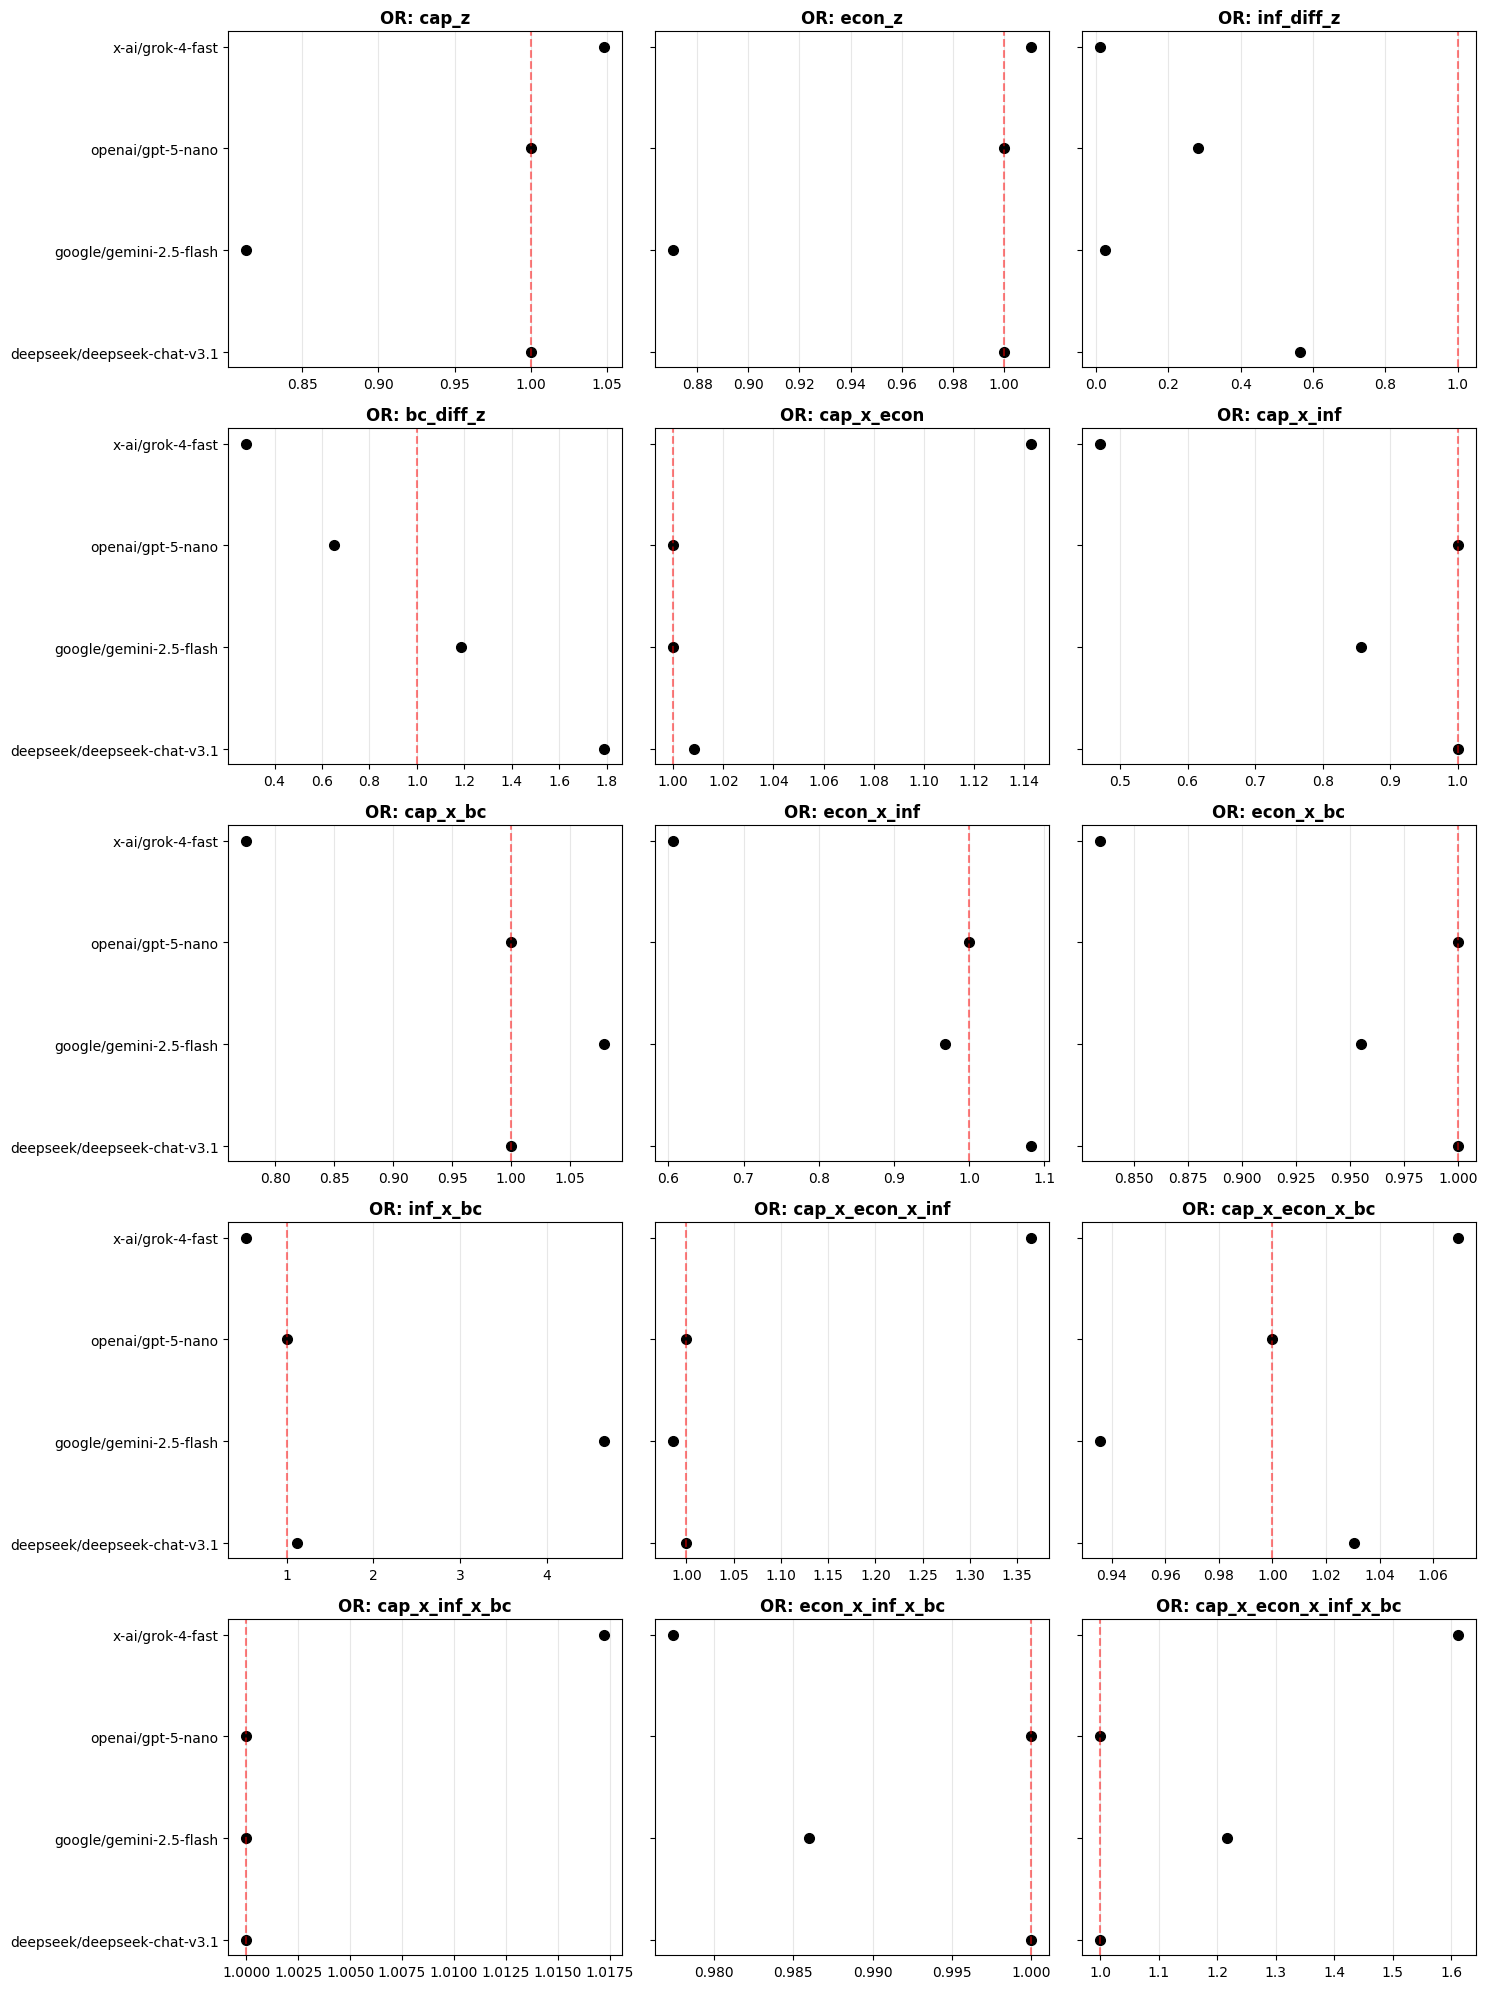

(                         Model    N      best_C  best_l1_ratio  AUROC_CV_best  \
 0  deepseek/deepseek-chat-v3.1  648    0.012743            0.1       0.849276   
 1      google/gemini-2.5-flash  646    0.615848            0.9       0.950310   
 2            openai/gpt-5-nano  648    0.012743            0.1       0.993333   
 3             x-ai/grok-4-fast  648  545.559478            0.1       0.969697   
 
    AUROC_fit  OR_cap_z  OR_econ_z  OR_inf_diff_z  OR_bc_diff_z  ...  \
 0   0.857016  1.000000   1.000000       0.563528      1.789010  ...   
 1   0.951436  0.813259   0.870582       0.026589      1.185673  ...   
 2   0.992860  1.000000   1.000000       0.281313      0.650860  ...   
 3   0.969224  1.048185   1.010636       0.011880      0.281228  ...   
 
    OR_cap_x_bc  OR_econ_x_inf  OR_econ_x_bc  OR_inf_x_bc  OR_cap_x_econ_x_inf  \
 0     1.000000       1.082374      1.000000     1.122185             1.000000   
 1     1.079019       0.967367      0.955256     4.661078     

In [17]:
run_dce_logit_strategy_three_elasticnet_cv()

In [18]:
def run_dce_rf_strategy_three_top5(
    results_df = full_results_df,
    strategy="strategy_three",
    min_obs=10,
    plot=True,
    show_tables=True,
    top_k=5,
    # Random Forest params
    n_estimators=500,
    max_depth=None,
    min_samples_leaf=1,
    random_state=42,
    n_jobs=-1,
    # CV params
    cv_folds=10
):
    """
    RandomForestClassifier for Strategy 3 (Dual Context: Capacity & Economic).

    Outputs:
      - per_model_df: AUROC (CV), N, plus bookkeeping
      - overall_df: pooled AUROC across models (from concatenated CV predictions)
      - importances_df: feature importances per model (long format)
      - Plots: 4 panels (one per model) with top_k feature importances
    """
    import pandas as pd
    import numpy as np
    import matplotlib.pyplot as plt
    from sklearn.ensemble import RandomForestClassifier
    from sklearn.metrics import roc_auc_score
    from sklearn.model_selection import StratifiedKFold

    # --- Robust display/printing ---
    def show_df(df, title):
        if not show_tables:
            return
        print("\n" + "=" * 60)
        print(title)
        print("=" * 60)
        try:
            from IPython.display import display
            display(df)
        except Exception:
            print(df.to_string(index=False))

    # --- Helper: NumPy z-score ---
    def np_zscore(series: pd.Series) -> pd.Series:
        arr = np.asarray(series, dtype=float)
        mu = np.nanmean(arr)
        sigma = np.nanstd(arr, ddof=0)
        if (not np.isfinite(sigma)) or sigma == 0:
            return pd.Series(np.full_like(arr, np.nan, dtype=float), index=series.index)
        return pd.Series((arr - mu) / sigma, index=series.index)

    # --- Feature engineering terms (same as your Strategy 3 logit spec) ---
    terms = [
        "cap_z", "econ_z", "inf_diff_z", "bc_diff_z",
        "cap_x_econ", "cap_x_inf", "cap_x_bc", "econ_x_inf", "econ_x_bc", "inf_x_bc",
        "cap_x_econ_x_inf", "cap_x_econ_x_bc", "cap_x_inf_x_bc", "econ_x_inf_x_bc",
        "cap_x_econ_x_inf_x_bc"
    ]

    def add_terms(m_df: pd.DataFrame) -> pd.DataFrame:
        m_df = m_df.copy()

        # z-scores
        m_df["inf_diff_z"] = np_zscore(m_df["inf_diff"])
        m_df["bc_diff_z"]  = np_zscore(m_df["bc_diff"])
        m_df["cap_z"]      = np_zscore(m_df["capacity_context"])
        m_df["econ_z"]     = np_zscore(m_df["economic_context"])

        # 2-way interactions
        m_df["cap_x_econ"] = m_df["cap_z"] * m_df["econ_z"]
        m_df["cap_x_inf"]  = m_df["cap_z"] * m_df["inf_diff_z"]
        m_df["cap_x_bc"]   = m_df["cap_z"] * m_df["bc_diff_z"]
        m_df["econ_x_inf"] = m_df["econ_z"] * m_df["inf_diff_z"]
        m_df["econ_x_bc"]  = m_df["econ_z"] * m_df["bc_diff_z"]
        m_df["inf_x_bc"]   = m_df["inf_diff_z"] * m_df["bc_diff_z"]

        # 3-way interactions
        m_df["cap_x_econ_x_inf"] = m_df["cap_x_econ"] * m_df["inf_diff_z"]
        m_df["cap_x_econ_x_bc"]  = m_df["cap_x_econ"] * m_df["bc_diff_z"]
        m_df["cap_x_inf_x_bc"]   = m_df["cap_x_inf"] * m_df["bc_diff_z"]
        m_df["econ_x_inf_x_bc"]  = m_df["econ_x_inf"] * m_df["bc_diff_z"]

        # 4-way
        m_df["cap_x_econ_x_inf_x_bc"] = m_df["cap_x_econ_x_inf"] * m_df["bc_diff_z"]

        return m_df.dropna(subset=["choice"] + terms)

    # --- 1) Filter strategy ---
    df = results_df[results_df["strategy"] == strategy].copy()
    print(f"Processing {strategy}: {len(df)} rows found.")
    if df.empty:
        return pd.DataFrame(), pd.DataFrame(), pd.DataFrame()

    # --- 2) Ensure numeric cols ---
    num_cols = [
        "infection_rate_selected", "infection_rate_non_selected",
        "npi_level_selected", "npi_level_non_selected",
        "capacity_context", "economic_context"
    ]
    for c in num_cols:
        if c in df.columns:
            df[c] = pd.to_numeric(df[c], errors="coerce")

    # --- 3) Choice & attribute reconstruction (same logic you used) ---
    df["choice"] = (df["selected_choice"] == df["pair"].str.split("-").str[0]).astype(int)
    df["inf_1"] = np.where(df["choice"] == 1, df["infection_rate_selected"], df["infection_rate_non_selected"])
    df["inf_2"] = np.where(df["choice"] == 1, df["infection_rate_non_selected"], df["infection_rate_selected"])
    df["npi_1"] = np.where(df["choice"] == 1, df["npi_level_selected"], df["npi_level_non_selected"])
    df["npi_2"] = np.where(df["choice"] == 1, df["npi_level_non_selected"], df["npi_level_selected"])

    df["bc_diff"] = df["npi_1"] - df["npi_2"]
    df["inf_diff"] = df["inf_1"] - df["inf_2"]

    # --- 4) Fit per model: CV AUROC + importances ---
    per_model_rows = []
    importances_rows = []

    pooled_y = []
    pooled_score = []

    # keep at most 4 panels as requested
    models_sorted = sorted(df["model"].dropna().unique())[:4]

    for model_name in models_sorted:
        m_df = df[df["model"] == model_name].copy()
        m_df = m_df.dropna(subset=["choice", "bc_diff", "inf_diff", "capacity_context", "economic_context"])
        if len(m_df) < min_obs:
            continue

        m_df = add_terms(m_df)
        if len(m_df) < min_obs:
            continue

        X = m_df[terms].to_numpy(dtype=float)
        y = m_df["choice"].to_numpy(dtype=int)

        # must have both classes
        vals, counts = np.unique(y, return_counts=True)
        if len(vals) < 2:
            continue

        # folds can’t exceed minority class count
        min_class = int(np.min(counts))
        n_splits = int(min(cv_folds, min_class))
        if n_splits < 2:
            continue

        # --- CV predicted probabilities for AUROC ---
        cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=random_state)
        y_score_cv = np.full_like(y, fill_value=np.nan, dtype=float)

        for fold_i, (tr, te) in enumerate(cv.split(X, y)):
            rf = RandomForestClassifier(
                n_estimators=n_estimators,
                max_depth=max_depth,
                min_samples_leaf=min_samples_leaf,
                random_state=random_state + fold_i,
                n_jobs=n_jobs
            )
            rf.fit(X[tr], y[tr])
            y_score_cv[te] = rf.predict_proba(X[te])[:, 1]

        auroc_cv = float(roc_auc_score(y, y_score_cv))

        pooled_y.append(y)
        pooled_score.append(y_score_cv)

        # --- Fit final RF on full data for feature_importances_ ---
        rf_full = RandomForestClassifier(
            n_estimators=n_estimators,
            max_depth=max_depth,
            min_samples_leaf=min_samples_leaf,
            random_state=random_state,
            n_jobs=n_jobs
        )
        rf_full.fit(X, y)
        importances = pd.Series(rf_full.feature_importances_, index=terms).sort_values(ascending=False)

        per_model_rows.append({
            "Model": model_name,
            "N": int(len(m_df)),
            "CV_folds_used": int(n_splits),
            "AUROC_CV": auroc_cv
        })

        for feat, imp in importances.items():
            importances_rows.append({
                "Model": model_name,
                "feature": feat,
                "importance": float(imp)
            })

    per_model_df = pd.DataFrame(per_model_rows).sort_values("Model").reset_index(drop=True)
    importances_df = pd.DataFrame(importances_rows)

    # --- Overall pooled AUROC from concatenated CV predictions ---
    overall_df = pd.DataFrame([{
        "Strategy": strategy,
        "Models_included": int(per_model_df["Model"].nunique()) if not per_model_df.empty else 0,
        "Total_N": int(per_model_df["N"].sum()) if not per_model_df.empty else 0,
        "AUROC_CV_pooled": (
            float(roc_auc_score(np.concatenate(pooled_y), np.concatenate(pooled_score)))
            if len(pooled_y) > 0 else np.nan
        )
    }])

    show_df(per_model_df, "Random Forest: per-model CV AUROC")
    show_df(overall_df, "Random Forest: pooled CV AUROC")
    # Optionally show top-5 table
    if show_tables and not importances_df.empty:
        top5_tbl = (
            importances_df.sort_values(["Model", "importance"], ascending=[True, False])
            .groupby("Model")
            .head(top_k)
            .reset_index(drop=True)
        )
        show_df(top5_tbl, f"Top {top_k} RF predictors per model (feature_importances_)")

    # --- 5) Plot 4 panels: top_k feature importances per model ---
    if plot and not importances_df.empty and not per_model_df.empty:
        models_for_plot = per_model_df["Model"].tolist()[:4]
        fig, axes = plt.subplots(2, 2, figsize=(14, 10))
        axes = np.array(axes).ravel()

        for i, model_name in enumerate(models_for_plot):
            ax = axes[i]
            d_imp = importances_df[importances_df["Model"] == model_name].copy()
            d_top = d_imp.sort_values("importance", ascending=False).head(top_k)

            # barh: smallest at bottom, largest at top
            d_top = d_top.sort_values("importance", ascending=True)

            auroc_val = float(per_model_df.loc[per_model_df["Model"] == model_name, "AUROC_CV"].iloc[0])
            ax.barh(d_top["feature"], d_top["importance"], color="steelblue", edgecolor="black", alpha=0.85)
            ax.set_title(f"{model_name} (CV AUROC={auroc_val:.3f})", fontsize=13, fontweight="bold")
            ax.set_xlabel("Feature importance")
            ax.grid(True, axis="x", alpha=0.25)

        # Hide unused panels if <4 models
        for j in range(len(models_for_plot), 4):
            axes[j].set_visible(False)

        plt.tight_layout()
        plt.show()

    return per_model_df, overall_df, importances_df


Processing strategy_three: 2590 rows found.

Random Forest: per-model CV AUROC


,Model,N,CV_folds_used,AUROC_CV
0,deepseek/deepseek-chat-v3.1,648,10,0.771566
1,google/gemini-2.5-flash,646,10,0.916052
2,openai/gpt-5-nano,648,10,0.997156
3,x-ai/grok-4-fast,648,10,0.993350



Random Forest: pooled CV AUROC


,Strategy,Models_included,Total_N,AUROC_CV_pooled
0,strategy_three,4,2590,0.952989



Top 5 RF predictors per model (feature_importances_)


,Model,feature,importance
0,deepseek/deepseek-chat-v3.1,inf_diff_z,0.241962
1,deepseek/deepseek-chat-v3.1,bc_diff_z,0.185629
2,deepseek/deepseek-chat-v3.1,inf_x_bc,0.111977
3,deepseek/deepseek-chat-v3.1,econ_x_inf,0.055421
4,deepseek/deepseek-chat-v3.1,cap_x_inf,0.052061
5,google/gemini-2.5-flash,inf_diff_z,0.483929
6,google/gemini-2.5-flash,inf_x_bc,0.106915
7,google/gemini-2.5-flash,bc_diff_z,0.082652
8,google/gemini-2.5-flash,econ_x_inf,0.049961
9,google/gemini-2.5-flash,cap_x_inf,0.045110


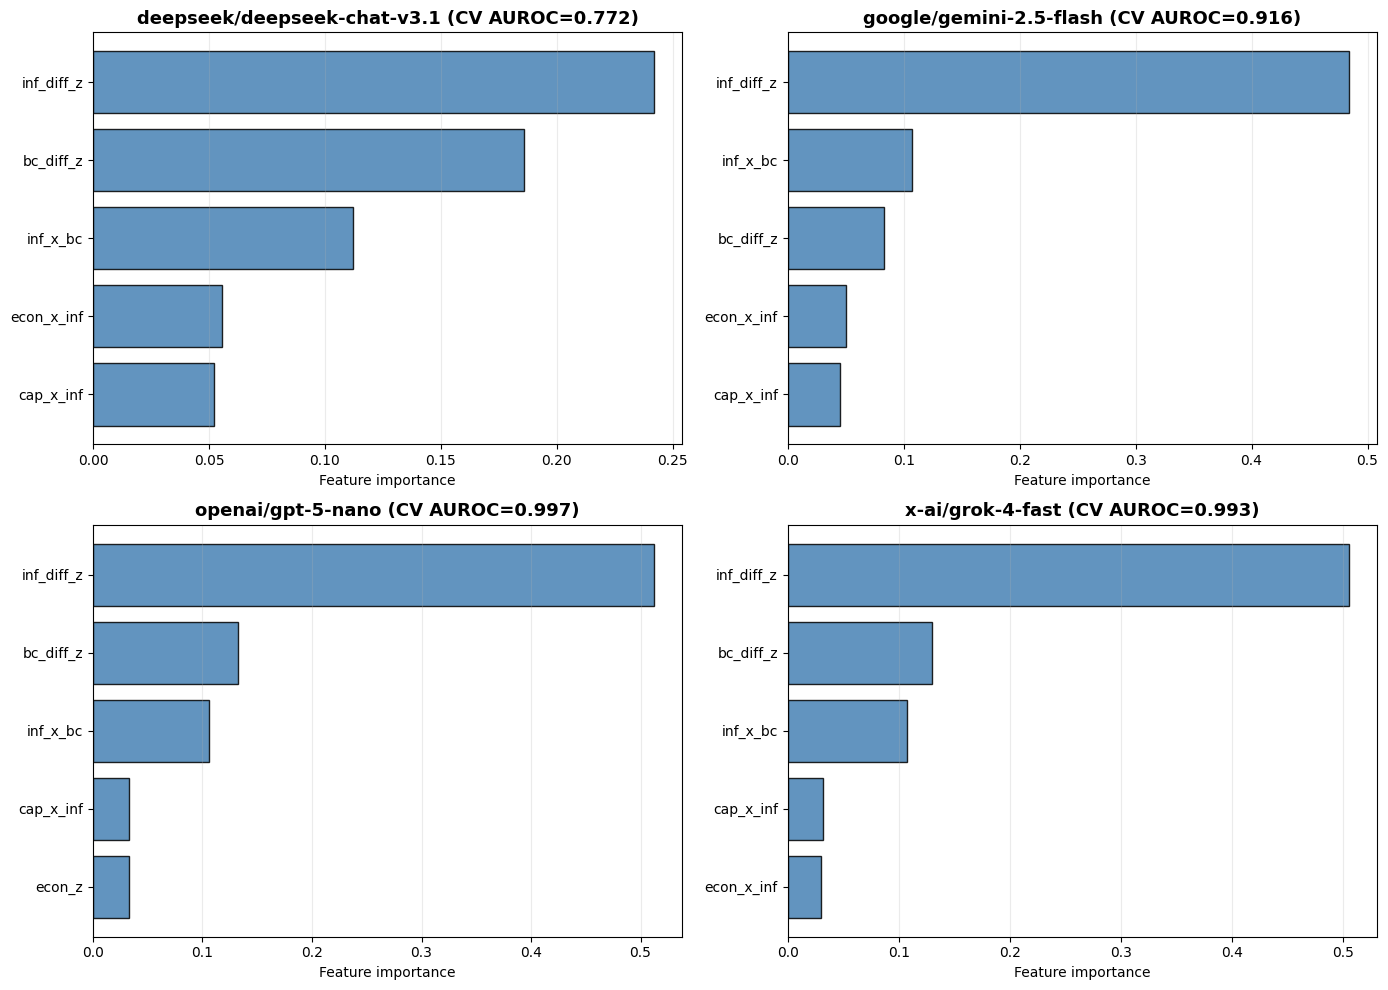

(                         Model    N  CV_folds_used  AUROC_CV
 0  deepseek/deepseek-chat-v3.1  648             10  0.771566
 1      google/gemini-2.5-flash  646             10  0.916052
 2            openai/gpt-5-nano  648             10  0.997156
 3             x-ai/grok-4-fast  648             10  0.993350,
          Strategy  Models_included  Total_N  AUROC_CV_pooled
 0  strategy_three                4     2590         0.952989,
                           Model                feature  importance
 0   deepseek/deepseek-chat-v3.1             inf_diff_z    0.241962
 1   deepseek/deepseek-chat-v3.1              bc_diff_z    0.185629
 2   deepseek/deepseek-chat-v3.1               inf_x_bc    0.111977
 3   deepseek/deepseek-chat-v3.1             econ_x_inf    0.055421
 4   deepseek/deepseek-chat-v3.1              cap_x_inf    0.052061
 5   deepseek/deepseek-chat-v3.1         cap_x_inf_x_bc    0.043648
 6   deepseek/deepseek-chat-v3.1              econ_x_bc    0.043549
 7   deepseek/deepse

In [19]:
run_dce_rf_strategy_three_top5()